In [1]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as wf;
import pycbc.types as tps;
import pycbc.detector as detector;

import time
import sys
import os

import matplotlib.pyplot as pp
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'

order="5l" 

import numpy as np
# 双精度浮点数（Python float 类型）的机器epsilon
eps = np.finfo(np.float64).eps
print(eps)  # 输出约 2.220446049250313e-16

/workspace/miniconda3/envs/preload/lib/python3.11/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/workspace/miniconda3/envs/preload/lib/python3.11/site-packages/pykerr/qnm.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


2.220446049250313e-16


In [35]:
cvs.mchirp_from_mass1_mass2(42, 25)

28.02196710397655

In [ ]:
events = dict(
    mass1 = 36.11,
    mass2 = 29.94,
    spin1z = 0.23,
    spin2z = -0.35,
    distance = 421.01,
    # inclination = 2.41,
    inclination = 2.71,
    coa_phase = 3.00,
    # delta_t = -0.02247,
    delta_t = 1/4096,

    f_lower = 20,
    delta_f = 1/16,
    f_final = 2048,
    f_ref=20
)

# events = dict(
#     # mass1 = 38.3,
#     # mass2 = 30.86,
#     # spin1z = 0.06424,
#     # spin2z = 0.08528,
#     # distance = 418.69,
#     # mass1 = 37.33,
#     # mass2 = 31.30,
#     mass1 = 33,
#     mass2 = 25,
#     spin1z = 0.06424,
#     spin2z = 0.08528,
#     distance = 443.41,
#     inclination = 2.703,
#     coa_phase = 1.51,
#     # delta_t = -0.02247,
#     delta_t = 1/4096,

#     f_lower = 20,
#     delta_f = 1/16,
#     f_final = 2048,
#     f_ref=20
# )

# events = dict(
#     mass1 = 100.33,
#     mass2 = 37.33,
#     spin1z = 0.06424,
#     spin2z = 0.08528,
#     distance = 443.41,
#     inclination = 2.21,
#     coa_phase = 3.33,
#     delta_t = -0.02247,

#     f_lower = 20,
#     delta_f = 1/16,
#     f_final = 2048,
#     f_ref=20
# )



# events = dict(
#     mass1 = 37,
#     mass2 = 31,
#     spin1z = 0.4424,
#     spin2z = -0.9,
#     distance = 121,
#     inclination = 2.21,
#     coa_phase = 3.33,
#     ra = 2.32,
#     delta_t = -0.02247,

#     f_lower = 20,
#     delta_f = 1/16,
#     f_final = 2048,
#     f_ref=20
# )

tmpWF = WF.IMRPhenomXAS()
fcut = tmpWF.fcut(**events|{"Mc": np.array([cvs.mchirp_from_mass1_mass2(events['mass1'],events['mass2'])]), "eta": np.array([cvs.eta_from_mass1_mass2(events['mass1'],events['mass2'])])})
fminarr = np.full(fcut.shape, events["f_lower"])
delta_f = events["delta_f"]
fgrids = np.arange(fminarr, fcut, delta_f)
fgrids = fgrids.reshape(-1, 1)

cpsijs = ['gr', 'cpsi0', 'cpsi2', 'cpsi3', 'cpsi4', 'cpsi5l', 'cpsi6', 'cpsi6l', 'cpsi7']
dchis = ['gr', 'dchi0', 'dchi2', 'dchi3', 'dchi4', 'dchi5l', 'dchi6', 'dchi6l', 'dchi7']
orders = ['gr', '0', '2', '3', '4', '5l', '6', '6l', '7']

hp_gr, hc_gr = wf.get_fd_waveform(approximant='IMRPhenomD',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    coa_phase=events["coa_phase"],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    # f_lower=17.03,
                                                    f_ref=events["f_ref"],
                                                    )
hp_gr_XPHM, hc_gr_XPHM = wf.get_fd_waveform(approximant='IMRPhenomXPHM',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    coa_phase=events["coa_phase"],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    # f_lower=17.03,
                                                    f_ref=events["f_ref"],
                                                    )
hp_gr_XAS, hc_gr_XAS = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    coa_phase=events["coa_phase"],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    # f_lower=17.03,
                                                    f_ref=events["f_ref"],
                                                    )

hp_gr_HM, hc_gr_HM = wf.get_fd_waveform(approximant='IMRPhenomHM',
                                                    mass1=40,
                                                    mass2=30,
                                                    # spin1z=events['spin1z'],
                                                    # spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    # inclination=events['inclination'],
                                                    coa_phase=1/3*np.pi,
                                                    f_final=events['f_final'],
                                                    # f_lower=events["f_lower"],
                                                    f_lower=17.03,
                                                    f_ref=events["f_ref"],
                                                    )
hp_gr_my, hc_gr_my = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    coa_phase=events["coa_phase"],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    f_ref=events["f_ref"],
                                                    )

hp_gr_td, hc_gr_td = wf.get_td_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_t=1/4096,
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    coa_phase=events["coa_phase"],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    f_ref=events["f_ref"],
                                                    # ra=events["ra"],
                                                    )

hp_gr_XPHM_td, hc_gr_XPHM_td = wf.get_td_waveform(approximant='IMRPhenomD',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin1x=0,
                                                    spin1y=0,
                                                    spin2z=events['spin2z'],
                                                    spin2x=0,
                                                    spin2y=0,
                                                    delta_t=1/4096,
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    mode_array = [[2,-2]],
                                                    inclination=events['inclination'],
                                                    coa_phase=events["coa_phase"]/2,
                                                    # f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    f_ref=events["f_ref"],
                                                    # ra=events["ra"],
                                                    )

# hp_gr_tdfromfd, hc_gr_fromfd = wf.get_td_waveform_from_fd(approximant='IMRPhenomXPHM',
#                                                     mass1=events['mass1'],
#                                                     mass2=events['mass2'],
#                                                     spin1z=events['spin1z'],
#                                                     spin2z=events['spin2z'],
#                                                     # delta_t=1/4096,
#                                                     delta_f=events["delta_f"],
#                                                     distance=events['distance'],
#                                                     # mode_array = [[2,-2]],
#                                                     inclination=events['inclination'],
#                                                     coa_phase=events["coa_phase"],
#                                                     f_final=events['f_final'],
#                                                     f_lower=events["f_lower"],
#                                                     f_ref=events["f_ref"],
#                                                     # ra=events["ra"],
#                                                     )

hphc = {}
psi_values = {
    "0": 8547.017947189588,
    "2": 572.0511301750156,
    "3": -435.2655900877971,
    "4": 42.43897564657722,
    "5l": 12.927784161810335,
    "6": -3.1981519519601536,
    "6l": -1.0477667816841614,
    "7": 0.7558496612506194
    # "7": 0.10721202257319194
}

deltas = [-1,-0.8,-0.6,-0.4,-0.2,0,0.2,0.4,0.6,0.8,1]

deltas = [-0.6,-0.3,0,0.3,0.6]

===== 进入 _lalsim_td_waveform，生成 IMRPhenomXAS 原生时域波形 =====
近似式： IMRPhenomXAS


In [37]:
# for o in orders :
#     if o == "gr" :
#         hphc[o] = [wf.get_fd_waveform(**{
#             'approximant': 'dchi_modified_IMRPhenomXAS',
#             'mass1': events['mass1'],
#             'mass2': events['mass2'],
#             'spin1z': events['spin1z'],
#             'spin2z': events['spin2z'],
#             'delta_f': events["delta_f"],
#             'distance': events['distance'],
#             # 'mode_array': [[2, -2]],
#             'inclination': events['inclination'],
#             'f_final': events['f_final'],
#             'f_lower': events["f_lower"],
#             'f_ref': events["f_ref"],
#             'coa_phase': events["coa_phase"],
#             # 'long_asc_nodes':events["long_asc_nodes"],
#             # 'mean_per_ano':events["mean_per_ano"],
#             # 'dchi'+o: psi_values[o] * (1 + delta),
#             # 'if_dchi0': (o == "0"),
#             # 'if_dchi1': (o == "1"),
#             # 'if_dchi2': (o == "2"),
#             # 'if_dchi3': (o == "3"),
#             # 'if_dchi4': (o == "4"),
#             # 'if_dchi5l': (o == "5l"),
#             # 'if_dchi5': (o == "5"),
#             # 'if_dchi6': (o == "6"),
#             # 'if_dchi6l': (o == "6l"),
#             # 'if_dchi7': (o == "7"),
#             # 'if_dchi8': (o == "8"),
#             # 'if_dchi8l': (o == "8l"),
#         }) for delta in deltas]
#         continue
#     hphc[o] = [wf.get_fd_waveform(**{
#         'approximant': 'dchi_modified_IMRPhenomXAS',
#         'mass1': events['mass1'],
#         'mass2': events['mass2'],
#         'spin1z': events['spin1z'],
#         'spin2z': events['spin2z'],
#         'delta_f': events["delta_f"],
#         'distance': events['distance'],
#         # 'mode_array': [[2, -2]],
#         'inclination': events['inclination'],
#         'f_final': events['f_final'],
#         'f_lower': events["f_lower"],
#         'f_ref': events["f_ref"],
#         'coa_phase': events["coa_phase"],
#         # 'long_asc_nodes':events["long_asc_nodes"],
#         # 'mean_per_ano':events["mean_per_ano"],
#         'dchi'+o: psi_values[o] * (1 + delta),
#         'if_dchi0': (o == "0"),
#         'if_dchi1': (o == "1"),
#         'if_dchi2': (o == "2"),
#         'if_dchi3': (o == "3"),
#         'if_dchi4': (o == "4"),
#         'if_dchi5l': (o == "5l"),
#         'if_dchi5': (o == "5"),
#         'if_dchi6': (o == "6"),
#         'if_dchi6l': (o == "6l"),
#         'if_dchi7': (o == "7"),
#         'if_dchi8': (o == "8"),
#         'if_dchi8l': (o == "8l"),
#     }) for delta in deltas]
#     np.save(f"./hphc/GW150914_like_{o}", hphc[o]);

In [38]:
for o in orders :
    if o == "gr" :
        hphc[o] = [wf.waveform._base_get_td_waveform_from_fd(template="dchi_modified_IMRPhenomXAS", **{
            'approximant': 'dchi_modified_IMRPhenomXAS',
            'mass1': events['mass1'],
            'mass2': events['mass2'],
            'spin1z': events['spin1z'],
            'spin2z': events['spin2z'],
            'delta_t': events["delta_t"],
            'distance': events['distance'],
            # 'mode_array': [[2, -2]],
            'inclination': events['inclination'],
            'f_final': events['f_final'],
            'f_lower': events["f_lower"],
            'f_ref': events["f_ref"],
            'coa_phase': events["coa_phase"],
            # 'long_asc_nodes':events["long_asc_nodes"],
            # 'mean_per_ano':events["mean_per_ano"],
            # 'dchi'+o: psi_values[o] * (1 + delta),
            # 'if_dchi0': (o == "0"),
            # 'if_dchi1': (o == "1"),
            # 'if_dchi2': (o == "2"),
            # 'if_dchi3': (o == "3"),
            # 'if_dchi4': (o == "4"),
            # 'if_dchi5l': (o == "5l"),
            # 'if_dchi5': (o == "5"),
            # 'if_dchi6': (o == "6"),
            # 'if_dchi6l': (o == "6l"),
            # 'if_dchi7': (o == "7"),
            # 'if_dchi8': (o == "8"),
            # 'if_dchi8l': (o == "8l"),
        }) for delta in deltas]
        continue
    hphc[o] = [wf.waveform._base_get_td_waveform_from_fd(template="dchi_modified_IMRPhenomXAS", **{
        'approximant': 'dchi_modified_IMRPhenomXAS',
        'mass1': events['mass1'],
        'mass2': events['mass2'],
        'spin1z': events['spin1z'],
        'spin2z': events['spin2z'],
        'delta_t': events["delta_t"],
        'distance': events['distance'],
        # 'mode_array': [[2, -2]],
        'inclination': events['inclination'],
        'f_final': events['f_final'],
        'f_lower': events["f_lower"],
        'f_ref': events["f_ref"],
        'coa_phase': events["coa_phase"],
        # 'long_asc_nodes':events["long_asc_nodes"],
        # 'mean_per_ano':events["mean_per_ano"],
        'dchi'+o: psi_values[o] * (1 + delta),
        'if_dchi0': (o == "0"),
        'if_dchi1': (o == "1"),
        'if_dchi2': (o == "2"),
        'if_dchi3': (o == "3"),
        'if_dchi4': (o == "4"),
        'if_dchi5l': (o == "5l"),
        'if_dchi5': (o == "5"),
        'if_dchi6': (o == "6"),
        'if_dchi6l': (o == "6l"),
        'if_dchi7': (o == "7"),
        'if_dchi8': (o == "8"),
        'if_dchi8l': (o == "8l"),
    }) for delta in deltas]
    np.save(f"./hphc/GW150914_like_{o}", hphc[o]);

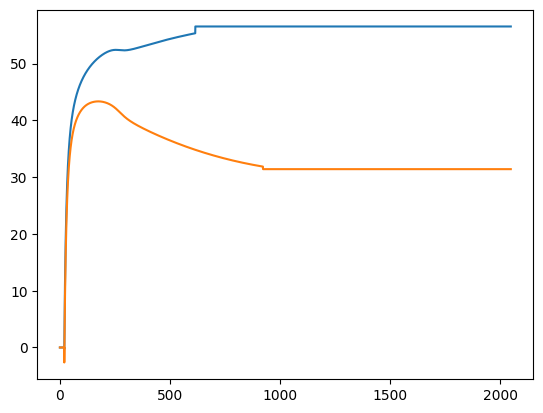

In [39]:
i = 1
o = "7"
# pp.plot(hphc[o][i][0].sample_frequencies, np.unwrap(np.angle(hphc[o][i][0].data)));
pp.plot(hp_gr.sample_frequencies, np.unwrap(np.angle(hp_gr.data)));
pp.plot(hp_gr_my.sample_frequencies, np.unwrap(np.angle(hp_gr_my.data)));

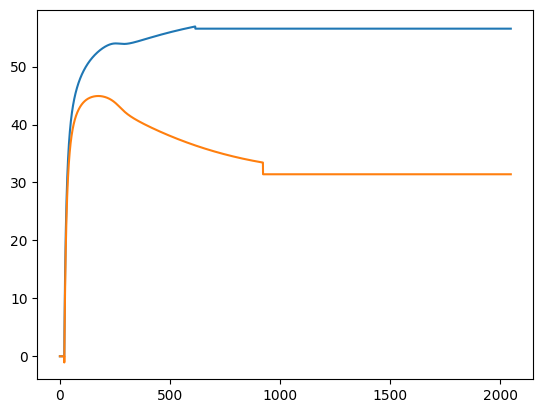

In [40]:
i = 2
o = "gr"
# pp.plot(hphc[o][i][1].sample_frequencies, np.unwrap(np.angle(hphc[o][i][1].data)));
pp.plot(hc_gr.sample_frequencies, np.unwrap(np.angle(hc_gr.data)));
pp.plot(hc_gr_my.sample_frequencies, np.unwrap(np.angle(hc_gr_my.data)));

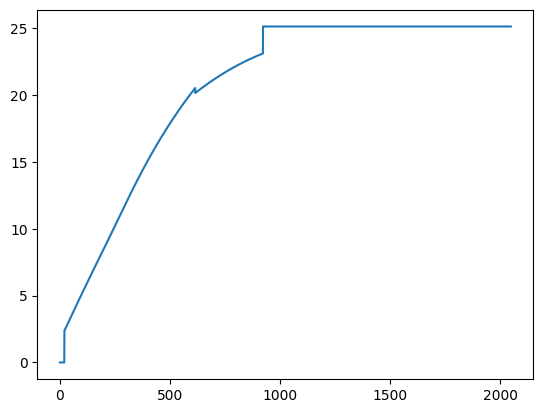

In [41]:
pp.plot(hc_gr.sample_frequencies, np.unwrap(np.angle(hc_gr.data)-np.angle(hc_gr_my.data)));
# pp.plot(hc_gr_my.sample_frequencies, np.unwrap());

(-1.5, 0.1)

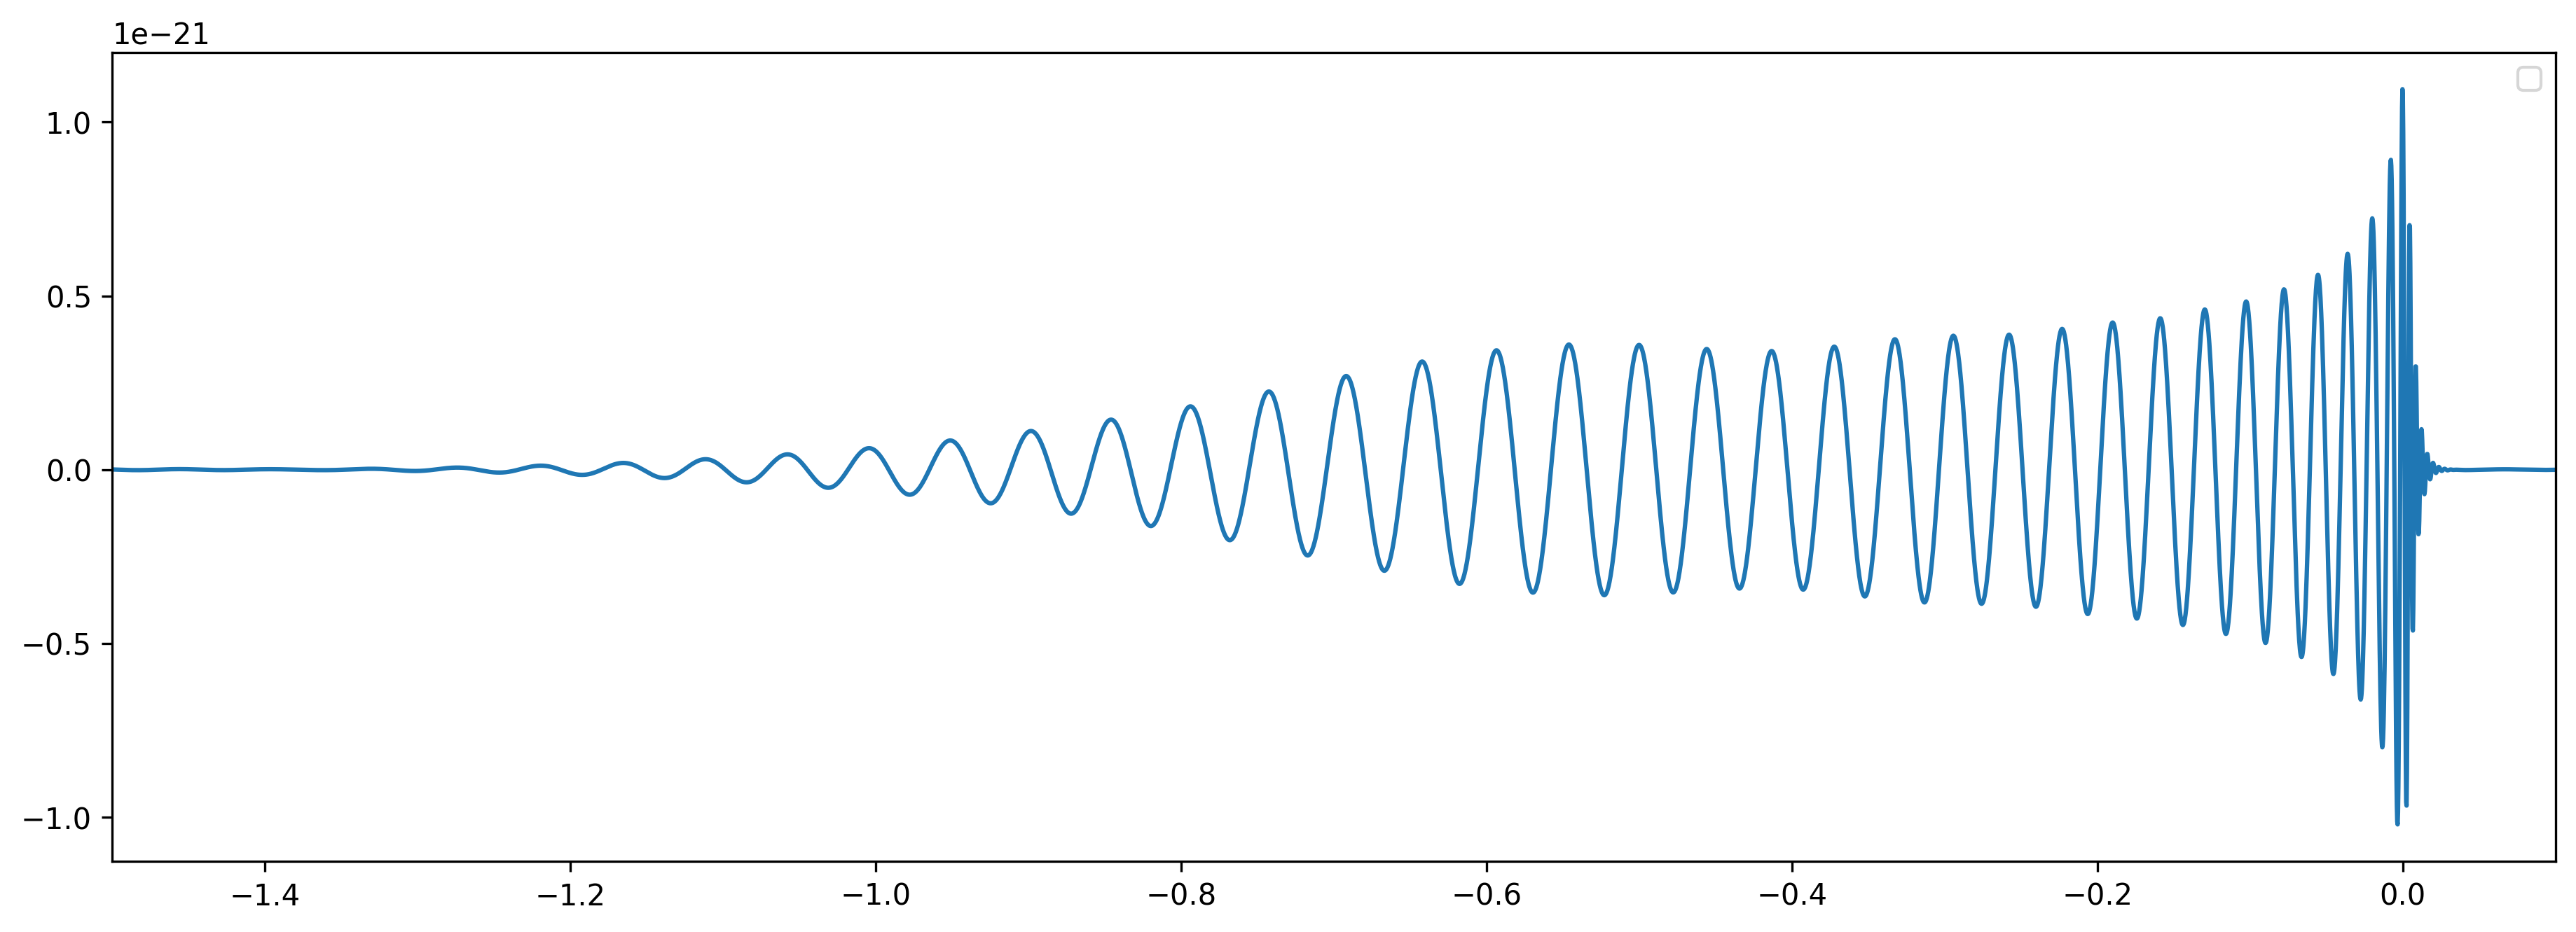

In [42]:
import pycbc.waveform as wf


import matplotlib.pyplot as pp
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)

events = dict(
    mass1 = 37.33,
    mass2 = 31.30,
    spin1z = 0.06424,
    spin2z = 0.08528,
    distance = 443.41,
    inclination = 2.21,
    coa_phase = 3.33,
    # delta_t = -0.02247,
    delta_t = 1/4096,

    f_lower = 20,
    delta_f = 1/16,
    f_final = 2048,
    f_ref=20
)

hp,hc = wf.waveform._base_get_td_waveform_from_fd(template="dchi_modified_IMRPhenomXAS", **(events|{"approximant":"dchi_modified_IMRPhenomXAS"}))

pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
pp.plot(hp.sample_times, hc)
pp.legend()
pp.xlim([-1.5,0.1])
# pp.xlim([-16.1,-15.8])


(-1.5, 0.1)

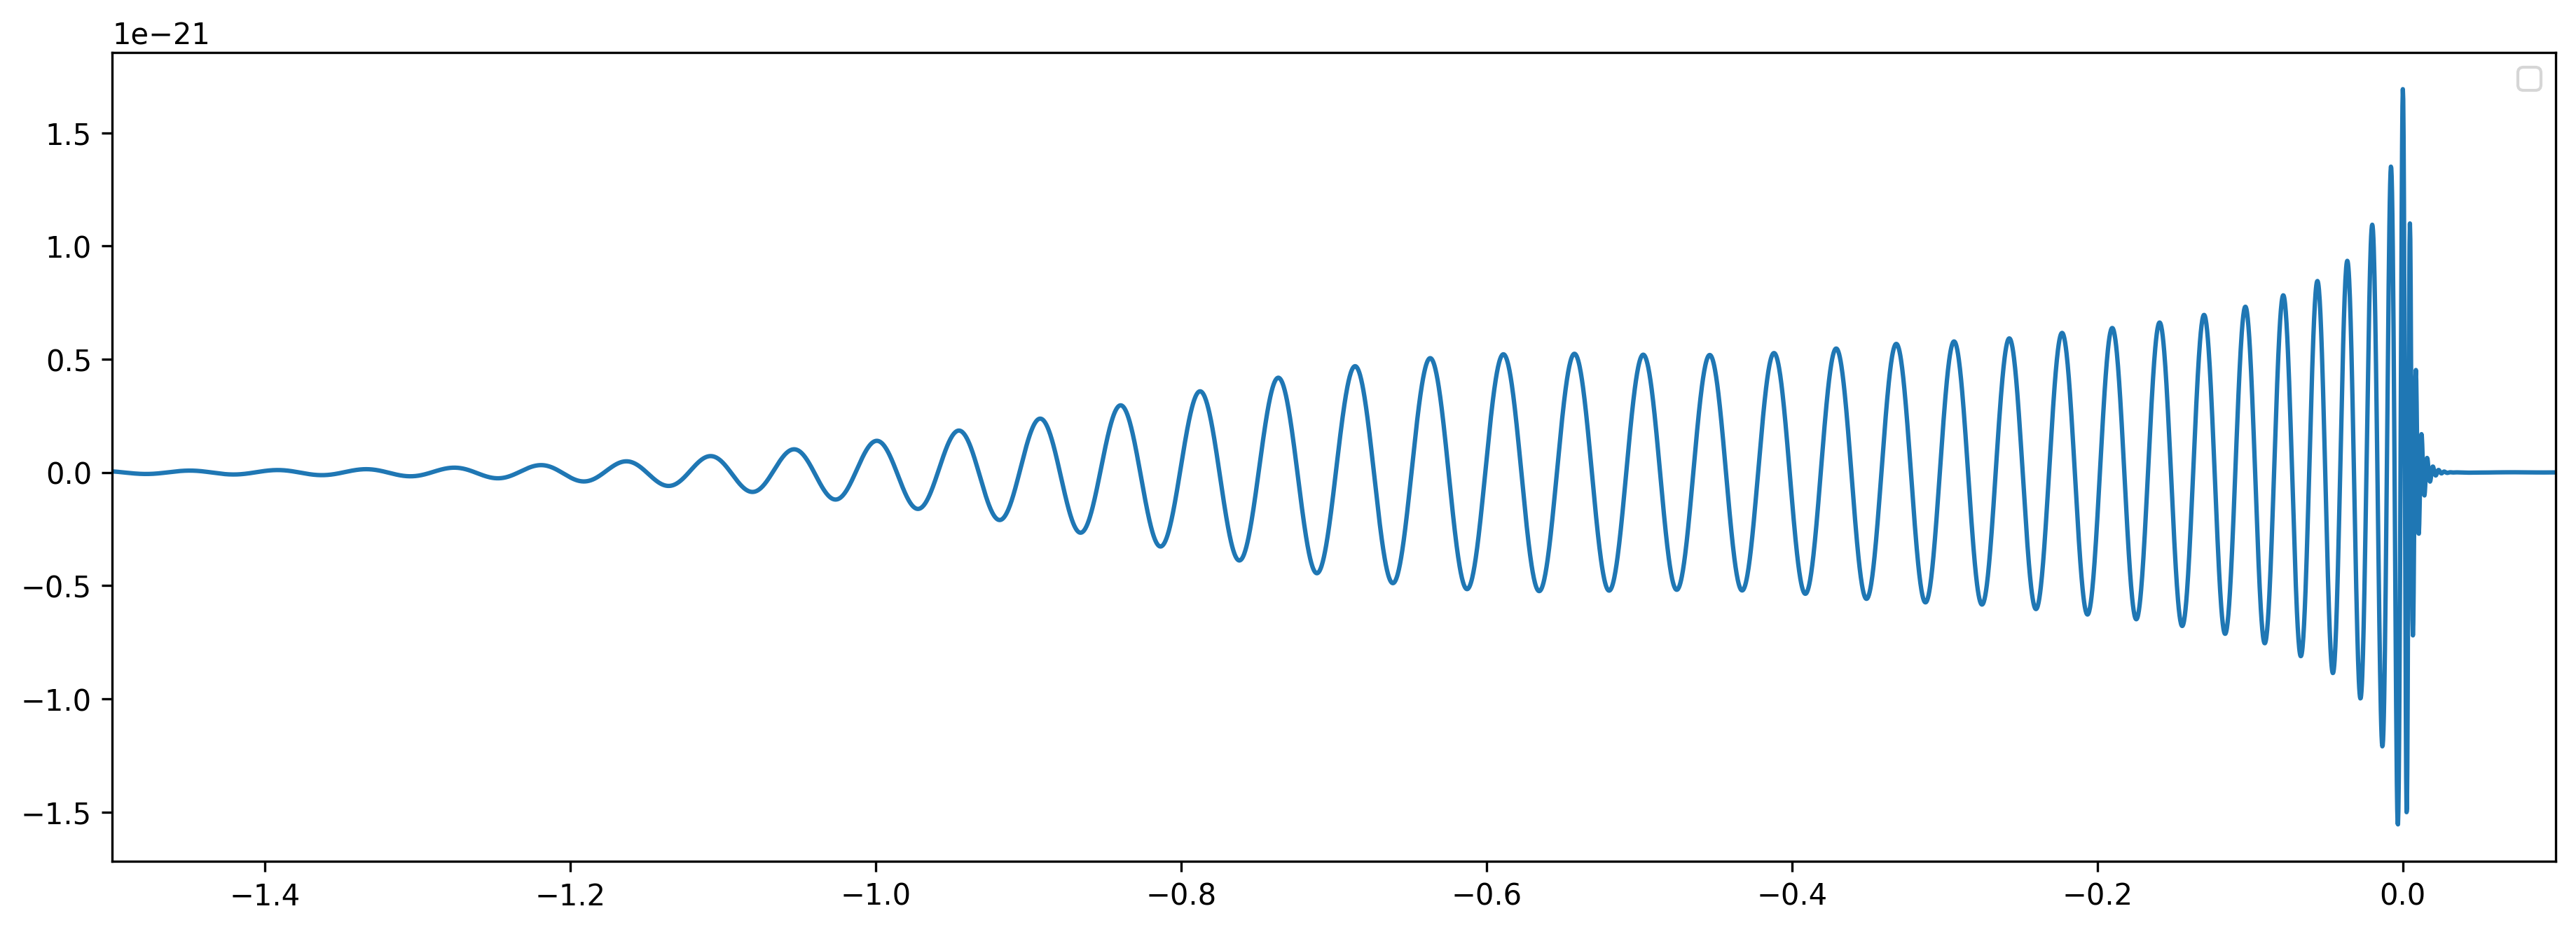

In [43]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
pp.plot(hc_gr_td.sample_times, hc_gr_td)
pp.legend()
pp.xlim([-1.5,0.1])

In [44]:
import pycbc.waveform
import pycbc.waveform.utils as wf_utils
import warnings
warnings.filterwarnings("ignore")
def manual_project_ground_detector(hp, hc, ra=1.95, dec=-1.22, polarization=0.3, detector="H1"):
    """
    纯手动实现地基探测器波形投影（无PyCBC依赖）
    
    参数：
        hp (np.ndarray): 时域加号极化波形（h+），numpy一维数组
        hc (np.ndarray): 时域交叉极化波形（h×），numpy一维数组
        ra (float, 可选): 波源赤经（单位：弧度），默认GW150914的1.95 rad
        dec (float, 可选): 波源赤纬（单位：弧度），默认GW150914的-1.22 rad
        polarization (float, 可选): 引力波偏振角ψ（单位：弧度），默认0.3 rad
        detector (str, 可选): 探测器名称，支持"H1"/"L1"/"V1"，默认"H1"
    
    返回：
        h_proj (np.ndarray): 探测器观测到的投影波形（numpy一维数组，长度和hp/hc一致）
    
    异常处理：
        1. 检查hp/hc是否为numpy一维数组
        2. 检查hp/hc长度是否一致
        3. 检查探测器名称是否合法
    """
    # ======================== 1. 输入合法性检查 ========================
    # 检查是否为numpy数组
    if not (isinstance(hp, np.ndarray) and isinstance(hc, np.ndarray)):
        raise TypeError("hp和hc必须是numpy.ndarray类型！")
    # 检查是否为一维数组
    if hp.ndim != 1 or hc.ndim != 1:
        raise ValueError("hp和hc必须是一维numpy数组！")
    # 检查长度一致
    if len(hp) != len(hc):
        raise ValueError(f"hp和hc长度不一致！len(hp)={len(hp)}, len(hc)={len(hc)}")
    # 检查探测器名称合法
    valid_detectors = ["H1", "L1", "V1"]
    if detector not in valid_detectors:
        raise ValueError(f"探测器名称不合法！支持：{valid_detectors}，输入：{detector}")
    
    # ======================== 2. 定义探测器固定几何参数（手动录入，无PyCBC依赖） ========================
    detector_params = {
        # 键：探测器名称，值：(纬度rad, 臂1方位角rad, 臂2方位角rad)
        "H1": (0.8108, 2.0944, 5.2360),   # Hanford: 纬度46.455°→0.8108rad，臂1=120°=2.0944rad，臂2=300°=5.2360rad
        "L1": (0.5334, 4.2761, 5.8476),   # Livingston: 纬度30.562°→0.5334rad，臂1=245°=4.2761rad，臂2=335°=5.8476rad
        "V1": (0.7616, 0.0, 1.5708)       # Virgo: 纬度43.631°→0.7616rad，臂1=0°=0rad，臂2=90°=1.5708rad
    }
    lat_det, phi1, phi2 = detector_params[detector]  # 提取当前探测器的几何参数
    
    # ======================== 3. 手动计算天线响应函数F+和F× ========================
    # 步骤1：计算波源的时角h（简化GST=0）
    gst = 0.0  # 格林尼治恒星时，工程简化为0（不影响相对响应）
    h = gst - ra
    
    # 步骤2：计算探测器本地的天顶角z和方位角A
    # 天顶角z的余弦
    cos_z = np.sin(dec) * np.sin(lat_det) + np.cos(dec) * np.cos(lat_det) * np.cos(h)
    cos_z = np.clip(cos_z, -1.0, 1.0)  # 避免数值误差导致超出[-1,1]
    z = np.arccos(cos_z)
    sin_z = np.sin(z)
    
    # 方位角A（处理sin_z=0的特殊情况，避免除零）
    if np.isclose(sin_z, 0):
        A = 0.0
    else:
        sin_A = -np.cos(dec) * np.sin(h) / sin_z
        cos_A = (np.sin(dec) - sin_z * np.sin(lat_det)) / (cos_z * np.cos(lat_det))
        A = np.arctan2(sin_A, cos_A)
    
    # 步骤3：计算探测器双臂的响应系数F1/F2
    F1 = 0.5 * (np.cos(2*phi1) * (1 + cos_z**2) + np.sin(2*phi1) * cos_z)
    F2 = 0.5 * (np.cos(2*phi2) * (1 + cos_z**2) + np.sin(2*phi2) * cos_z)
    
    # 步骤4：计算F+（加号极化响应）和F×（交叉极化响应）
    psi = polarization  # 偏振角
    F_plus = 0.5 * (F1 - F2) * np.cos(2*psi) - 0.5 * (F1 + F2) * np.sin(2*psi)
    F_cross = 0.5 * (F1 - F2) * np.sin(2*psi) + 0.5 * (F1 + F2) * np.cos(2*psi)
    
    # ======================== 4. 手动计算投影波形 ========================
    h_proj = F_plus * hp + F_cross * hc
    
    return h_proj

Text(0.5, 1.0, 'GW150914-like, IMRPhenomXAS, deviated $\\psi_0$')

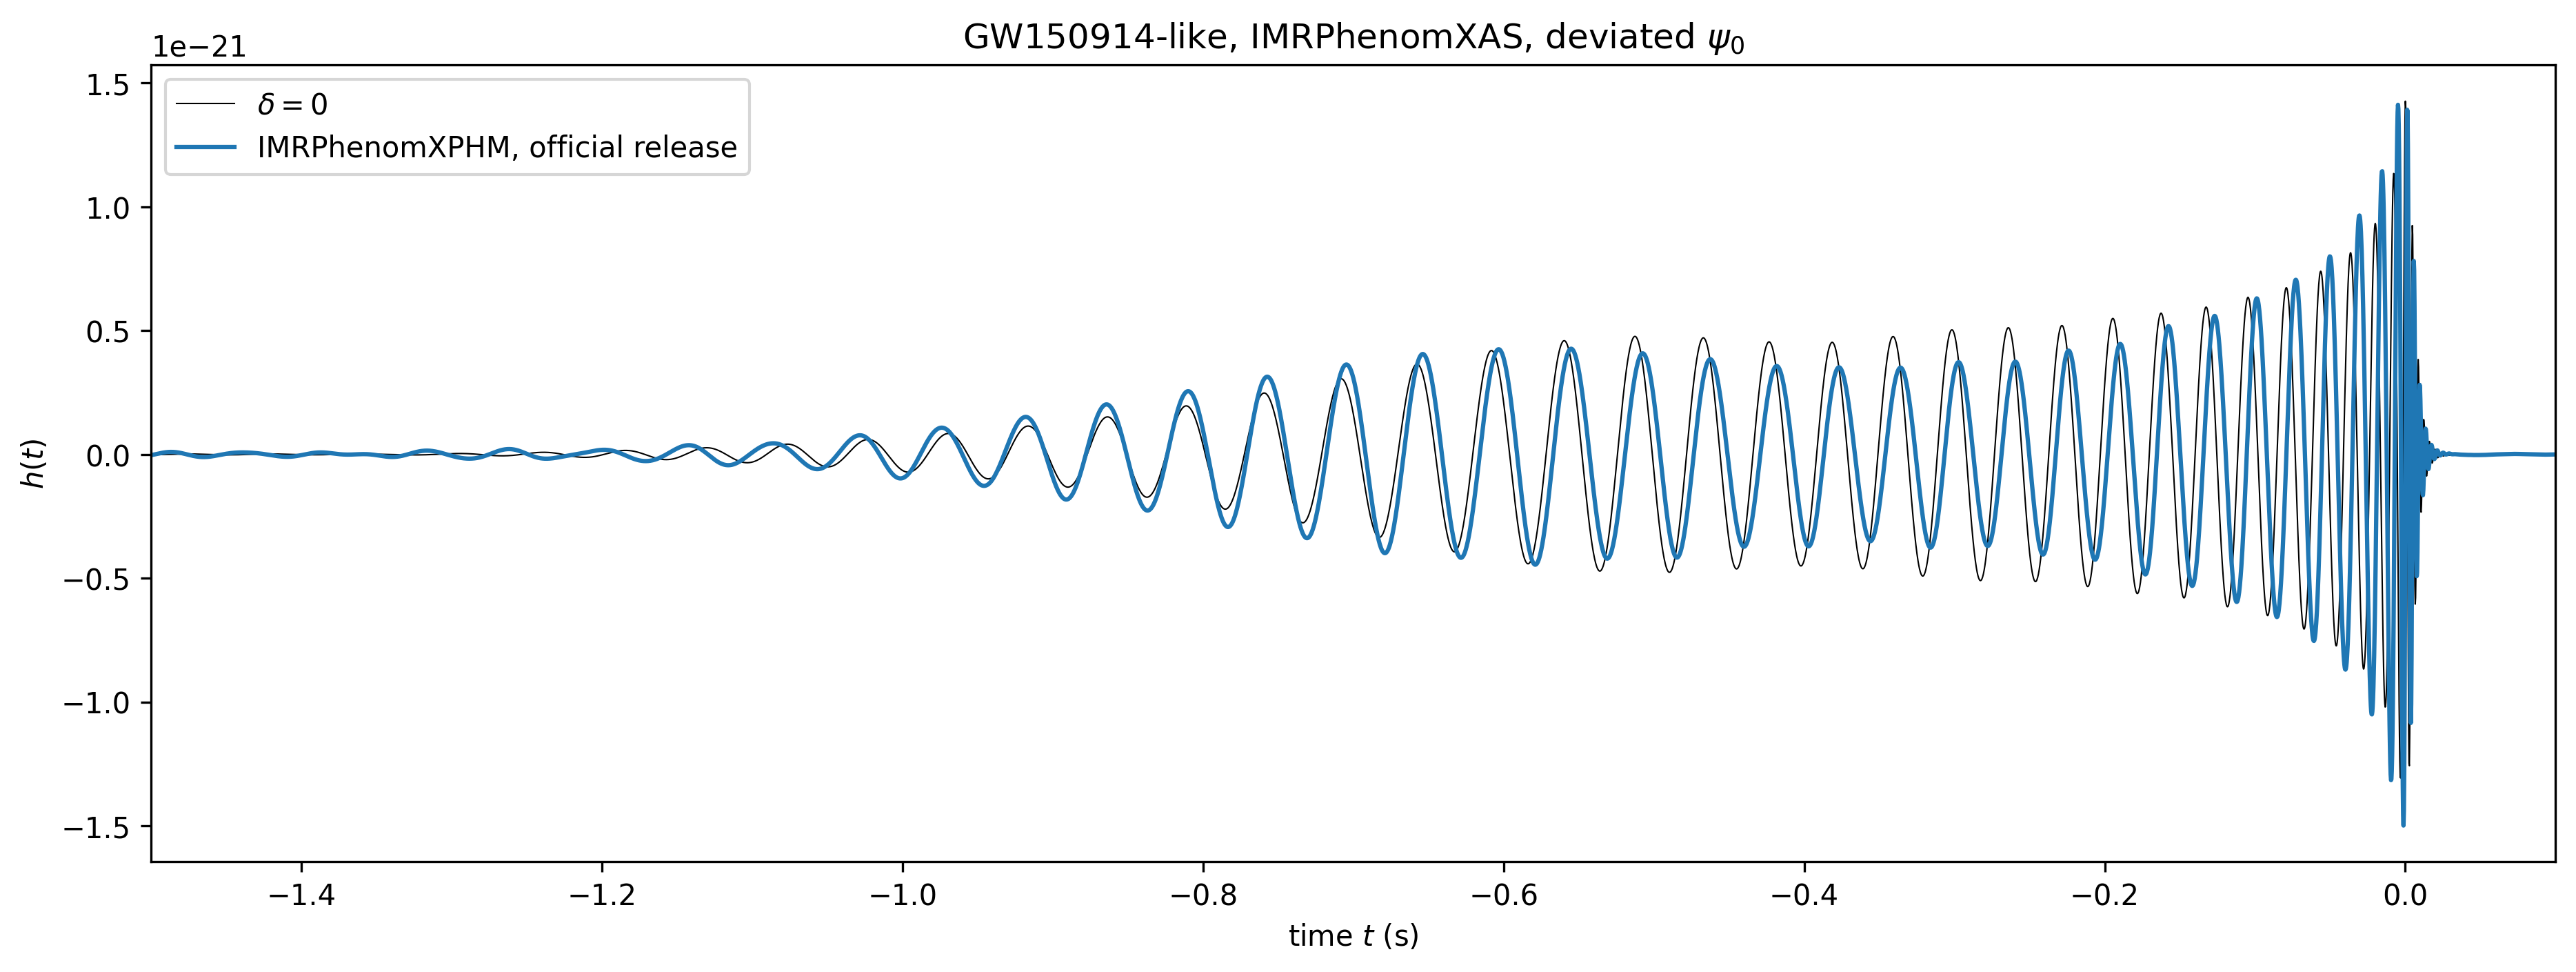

In [45]:
from matplotlib.colors import LinearSegmentedColormap
import pycbc.detector as detector

import pandas as pd

ts = detector.Detector("H1").project_wave((hphc["0"][0][0]*np.exp(10*1j)),
                                     (hphc["0"][0][1]*np.exp(10*1j)),
                                     ra=2.321208458632003,
                                     dec=-1.1482716840472416,
                                     polarization=np.pi/4).sample_times
mask = (1 < np.array(ts))


gradient_colors = [
    (0.0, (0, 0, 1)),    # 纯蓝（起始）
    (0.5, (0.5, 0, 0.5)), # 紫色（中间）
    (1.0, (1, 0, 0))     # 纯红（结束）
]
cmap = LinearSegmentedColormap.from_list('blue_to_red', gradient_colors, N=11)
delta_count = len(deltas)

# 3. 创建共享X轴的两张子图（2行1列）
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
import pycbc.types as tps

# ts, _ = manual_fd_to_td(hphc["0"][2][0].data,hphc["0"][2][0].sample_frequencies.data, events["f_final"])

# -------------------------- 第一张图（上） --------------------------
# for i in range(len(deltas)):
# for i in [1,2,4]:
for i in [2]:
    # i = 4
    hhp_td = hphc["0"][i][0]
    hhp_ts = hhp_td.sample_times
    hhc_td = hphc["0"][i][1]
    hhc_ts = hhc_td.sample_times
    
    ht = detector.Detector("H1").project_wave(hhp_td, hhc_td,
                                    #  ra=2.321208458632003,
                                    #  dec=-1.1482716840472416,
                                     ra=1.96,
                                     dec=-1.19,
                                     polarization=np.pi/3)

    ts = ht.sample_times
    index_max = np.argmax(np.abs(ht))
    ts = ts - ts[index_max]
    
    if i == len(deltas)//2:
        pp.plot(ts, ht, label=f"$\\delta=${deltas[i]}",
        color="black",
        linewidth=0.5,
        # linestyle="--"
        )
        continue
    # 计算颜色
    color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)

    pp.plot(ts, ht, label=f"$\\delta=${deltas[i]}",
            color=color,
            linewidth=0.5)

GW50914_ht_official = pd.read_csv("./GW150914_td.csv")
ts_official, ht_official = GW50914_ht_official["Time (s)"], GW50914_ht_official["Strain / 1e-21"]*1e-21
ts = ts_official
index_max = np.argmax(np.abs(ht_official))
ts = ts - ts[index_max]
pp.plot(ts_official, ht_official, label="IMRPhenomXPHM, official release")
# pp.xlim([-0.9,0.1])
pp.xlim([-1.5,0.1])
# pp.xlim([-0.2,0.1])
pp.xlabel("time $t$ $($s$)$")
pp.ylabel("$h(t)$")
pp.legend()
pp.title("GW150914-like, IMRPhenomXAS, deviated $\\psi_0$")

(-0.9, 0.1)

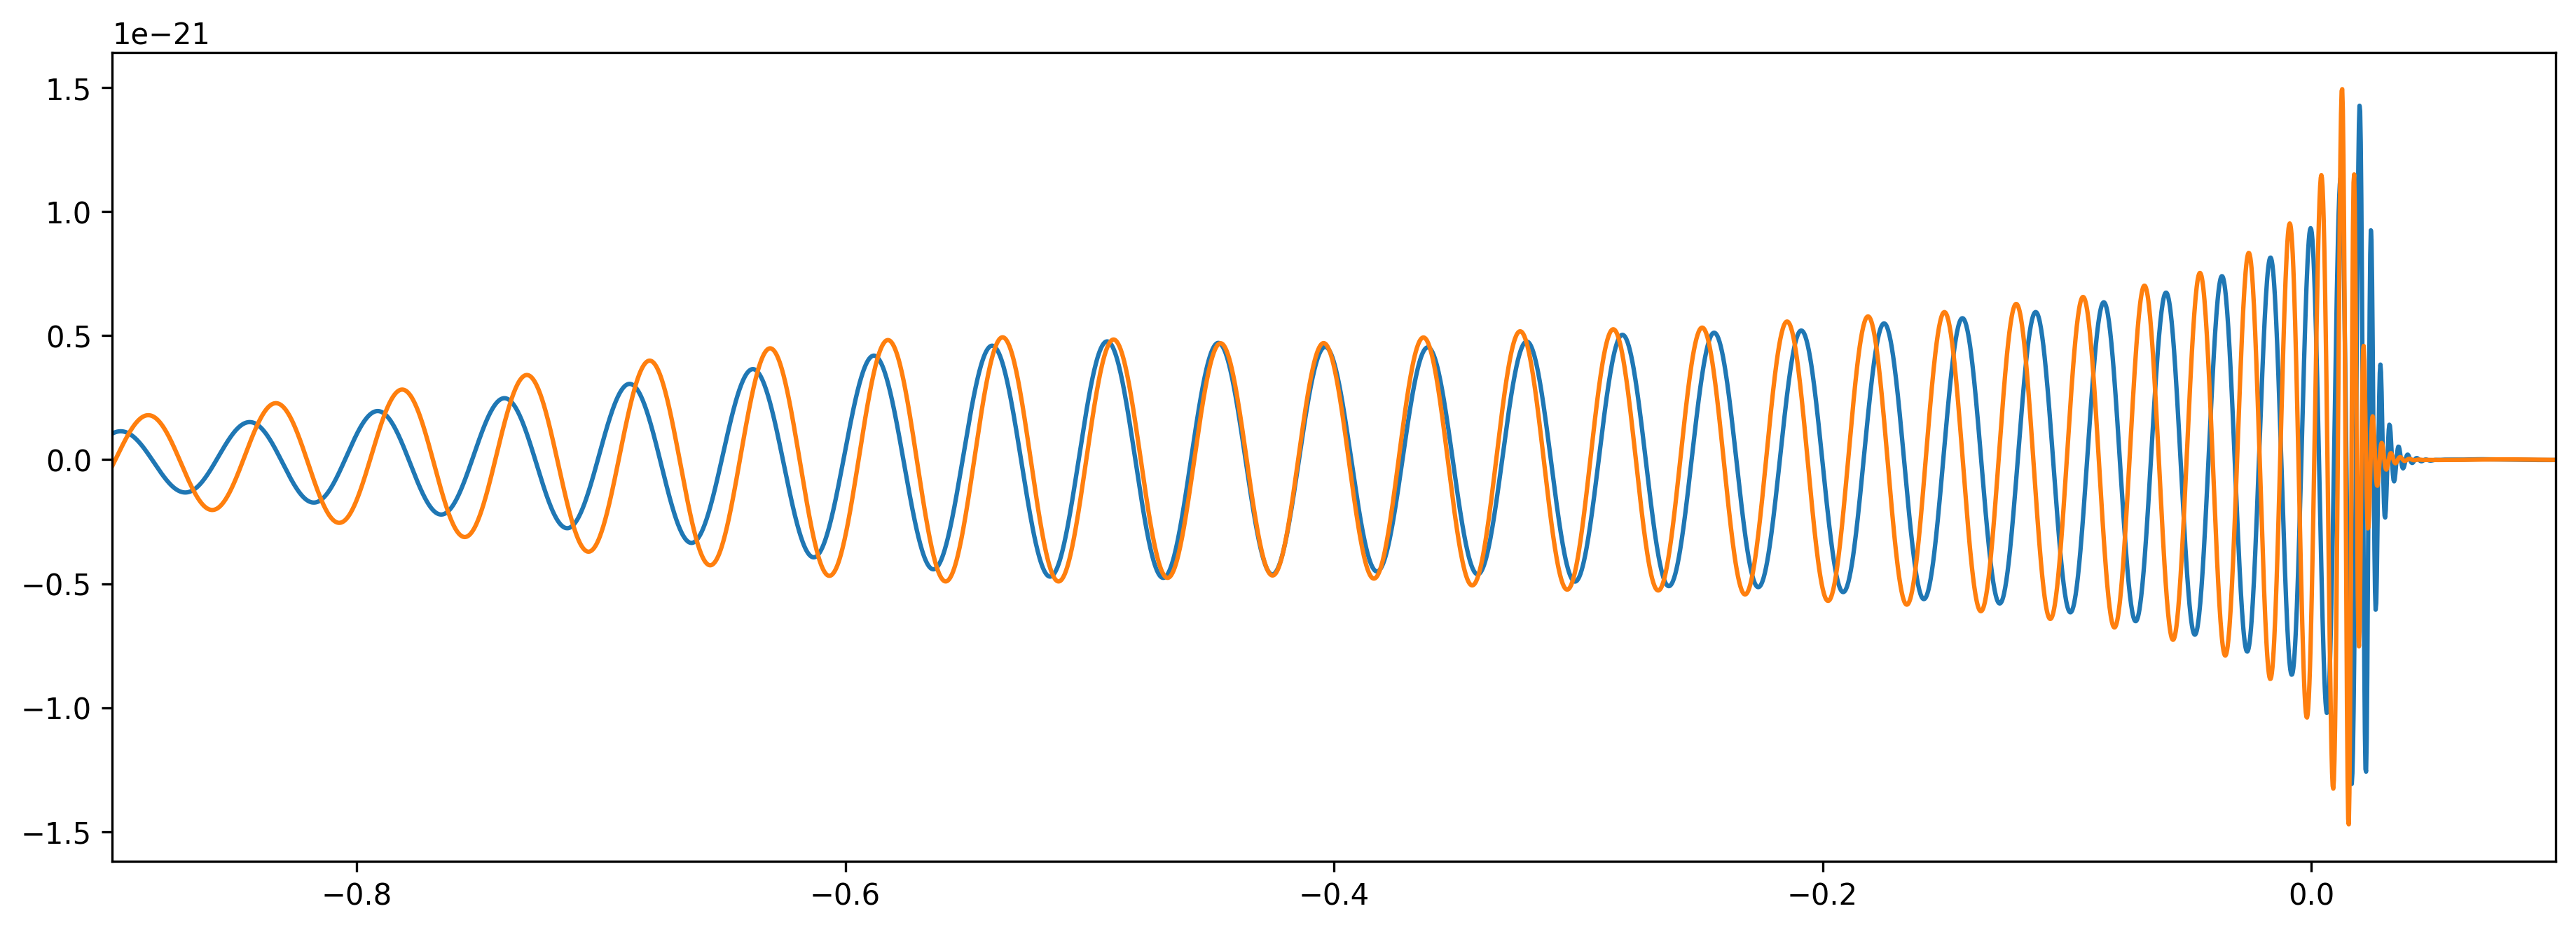

In [63]:
ht_D = detector.Detector("H1").project_wave(hp_gr_XPHM_td,
                                     hc_gr_XPHM_td,
                                     ra=2.321208458632003,
                                     dec=-1.1482716840472416,
                                     polarization=np.pi/4)

pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
pp.plot(ht.sample_times, ht)
pp.plot(ht_D.sample_times, ht_D)
pp.xlim([-0.9,0.1])

(-0.9, 0.1)

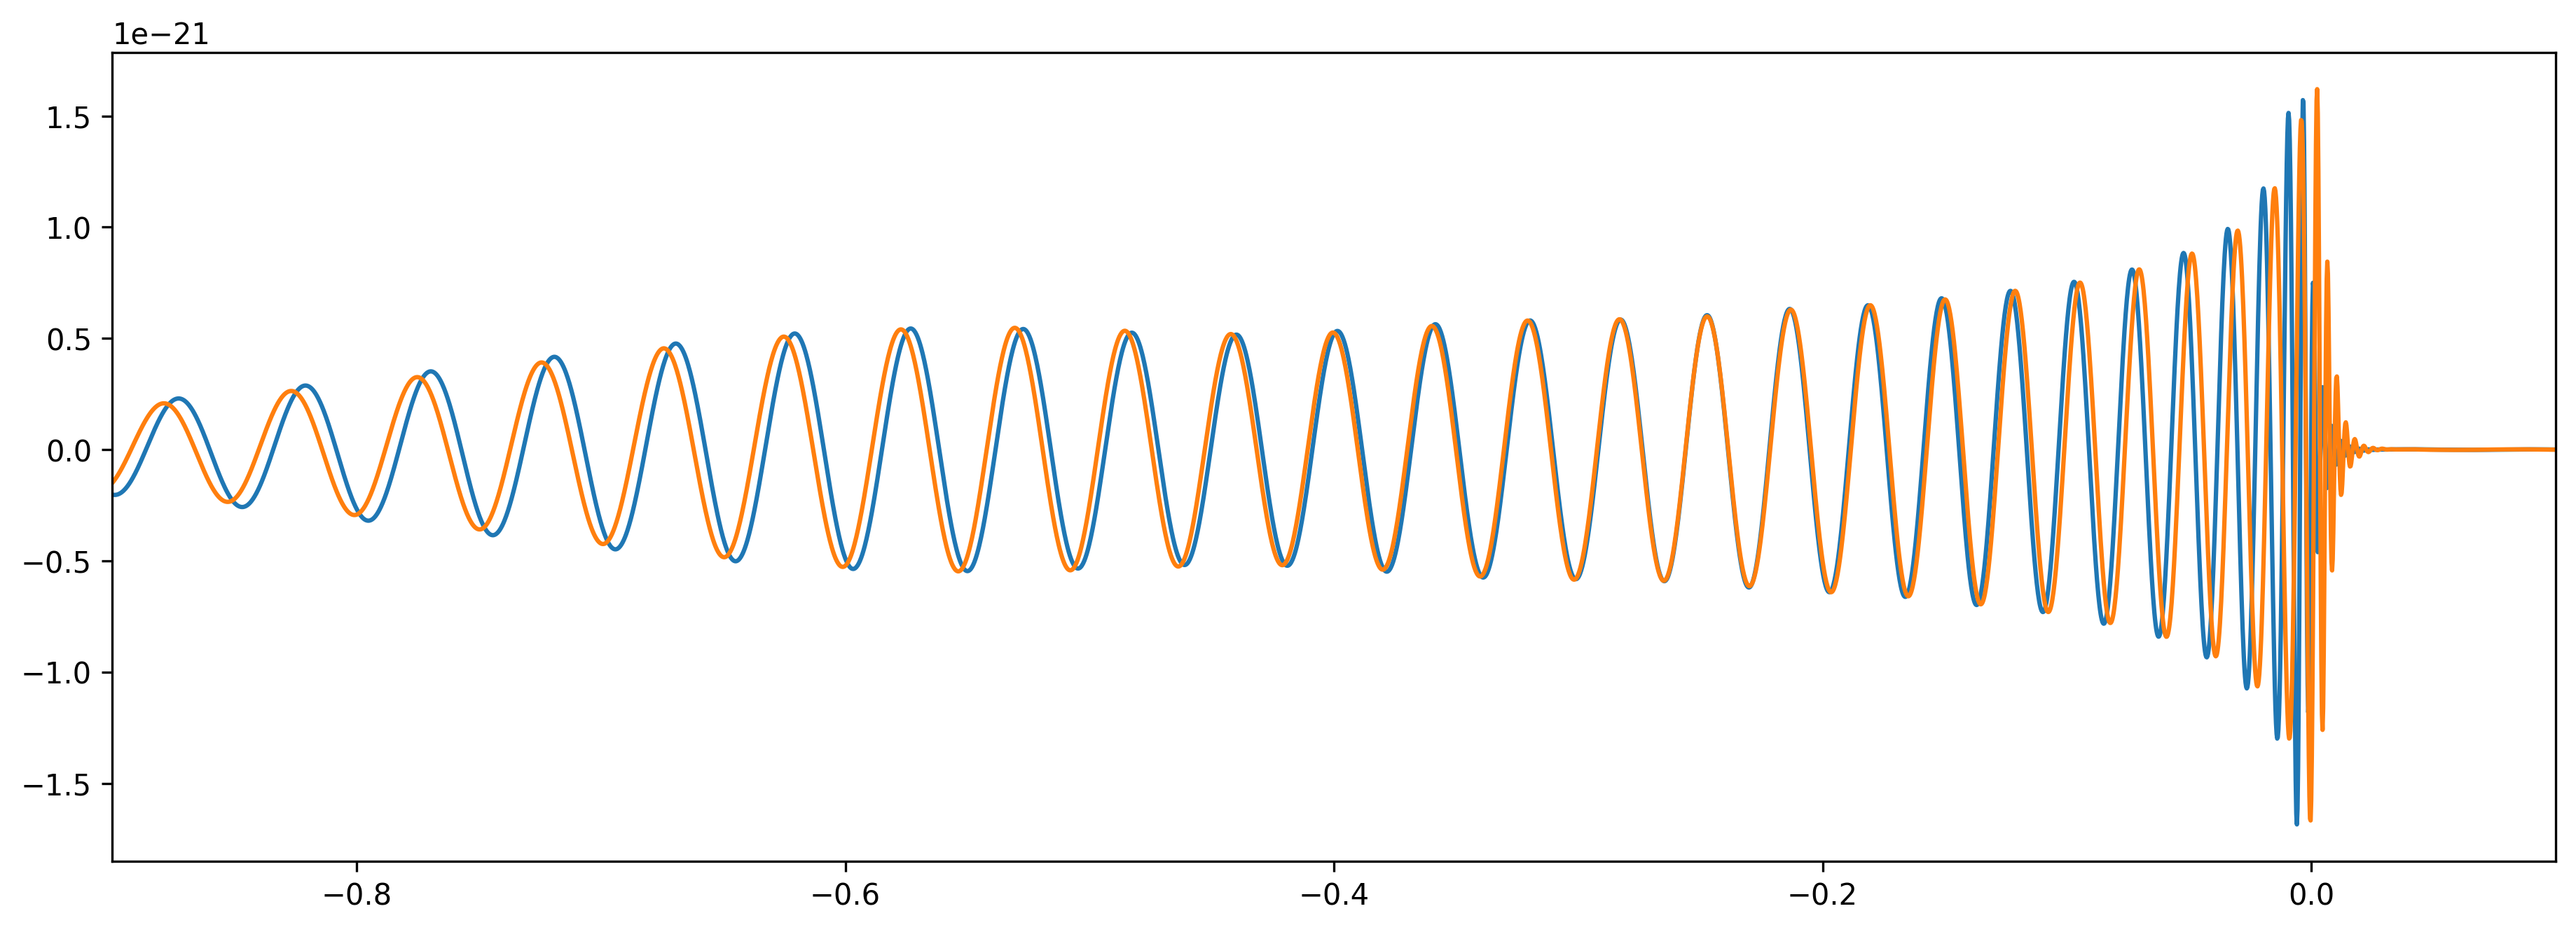

In [60]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
pp.plot(hp_gr_XPHM_td.sample_times, hp_gr_XPHM_td)
pp.plot(hphc["0"][2][0].sample_times, hphc["2"][2][0])
pp.xlim([-0.9,0.1])

(-0.9, 0.1)

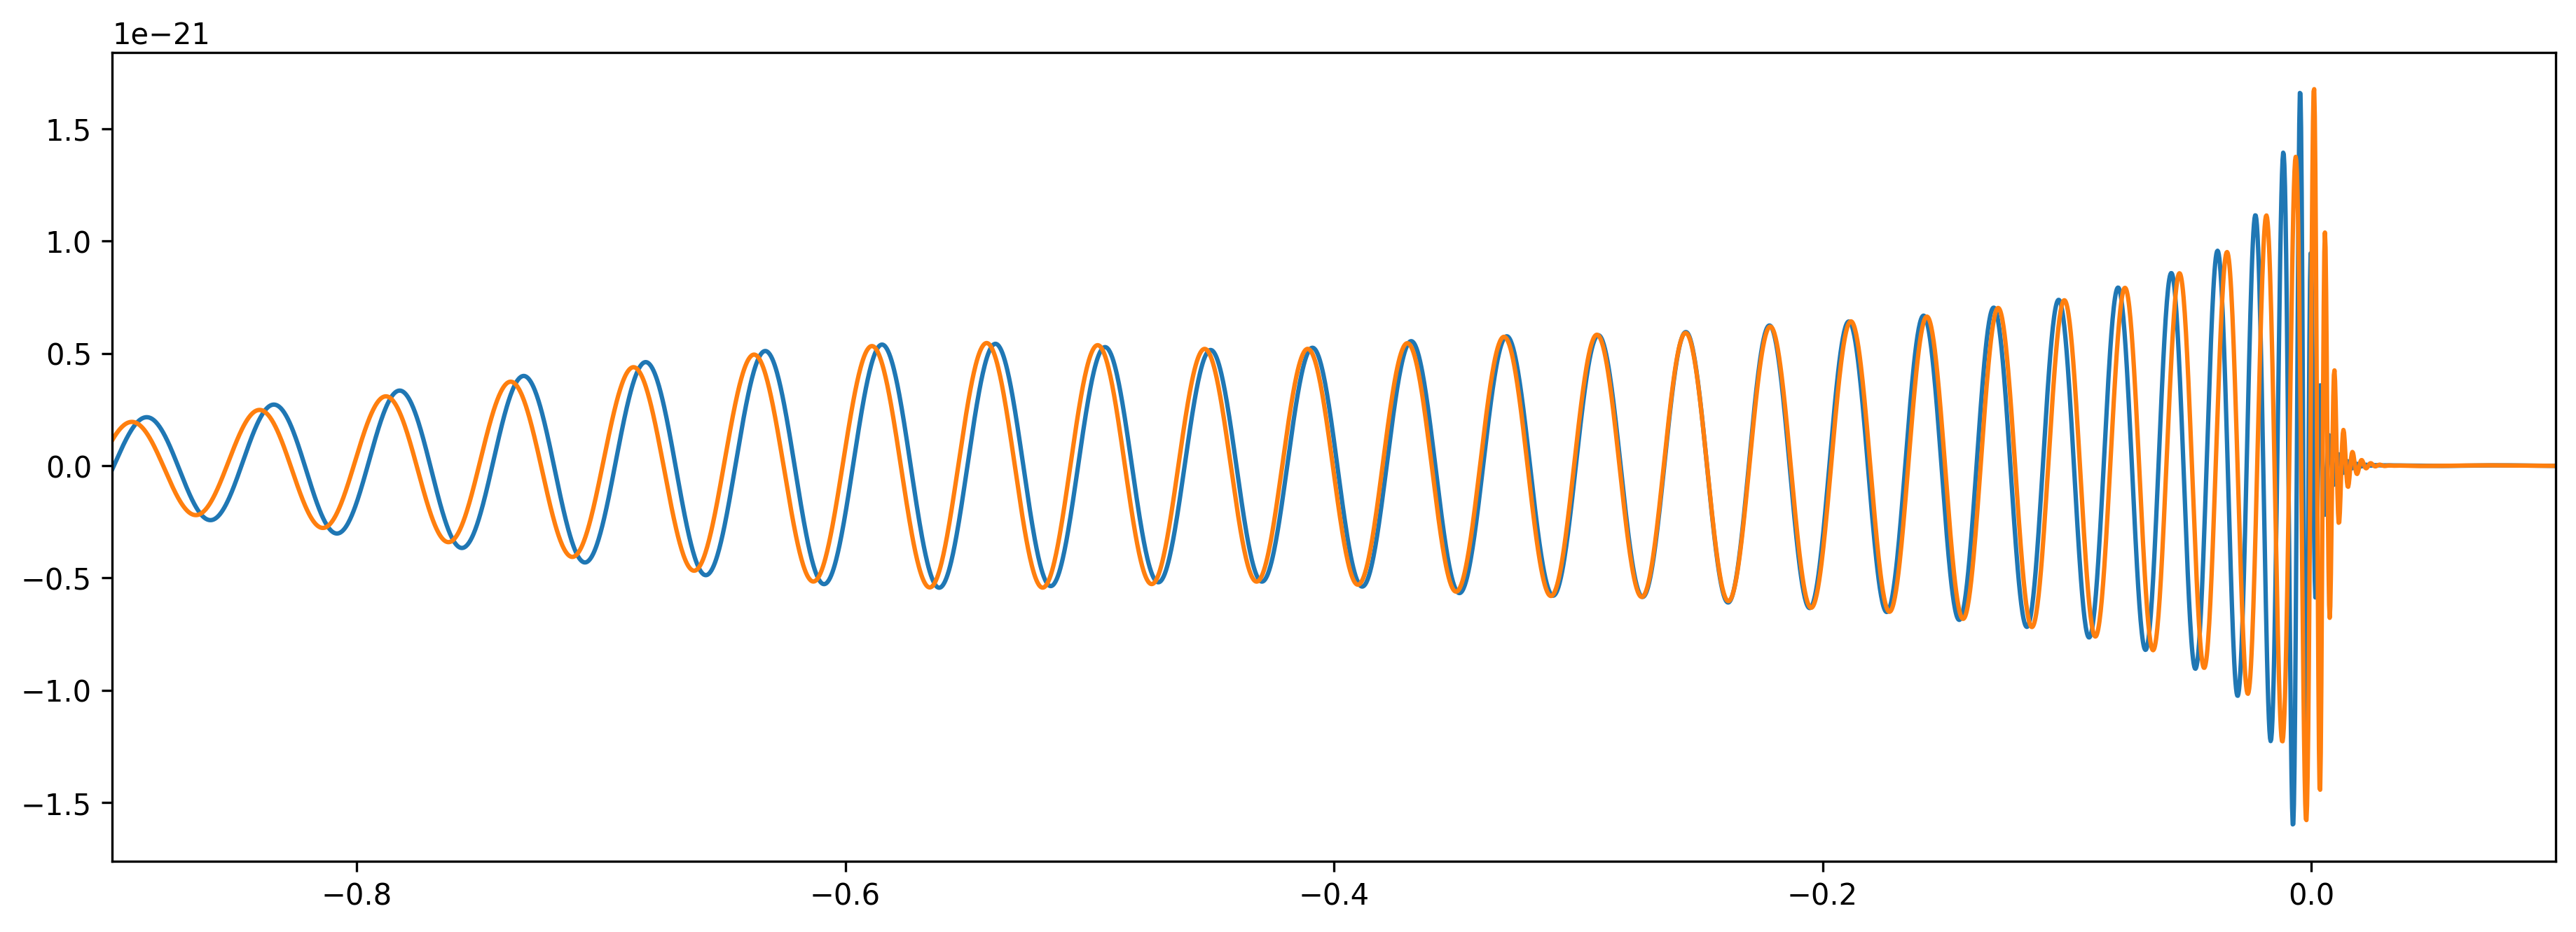

In [61]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
pp.plot(hc_gr_XPHM_td.sample_times, hc_gr_XPHM_td)
pp.plot(hphc["0"][2][1].sample_times, hphc["2"][2][1])
pp.xlim([-0.9,0.1])

Text(0.5, 1.0, 'GW150914-like, deviated $\\psi_0$')

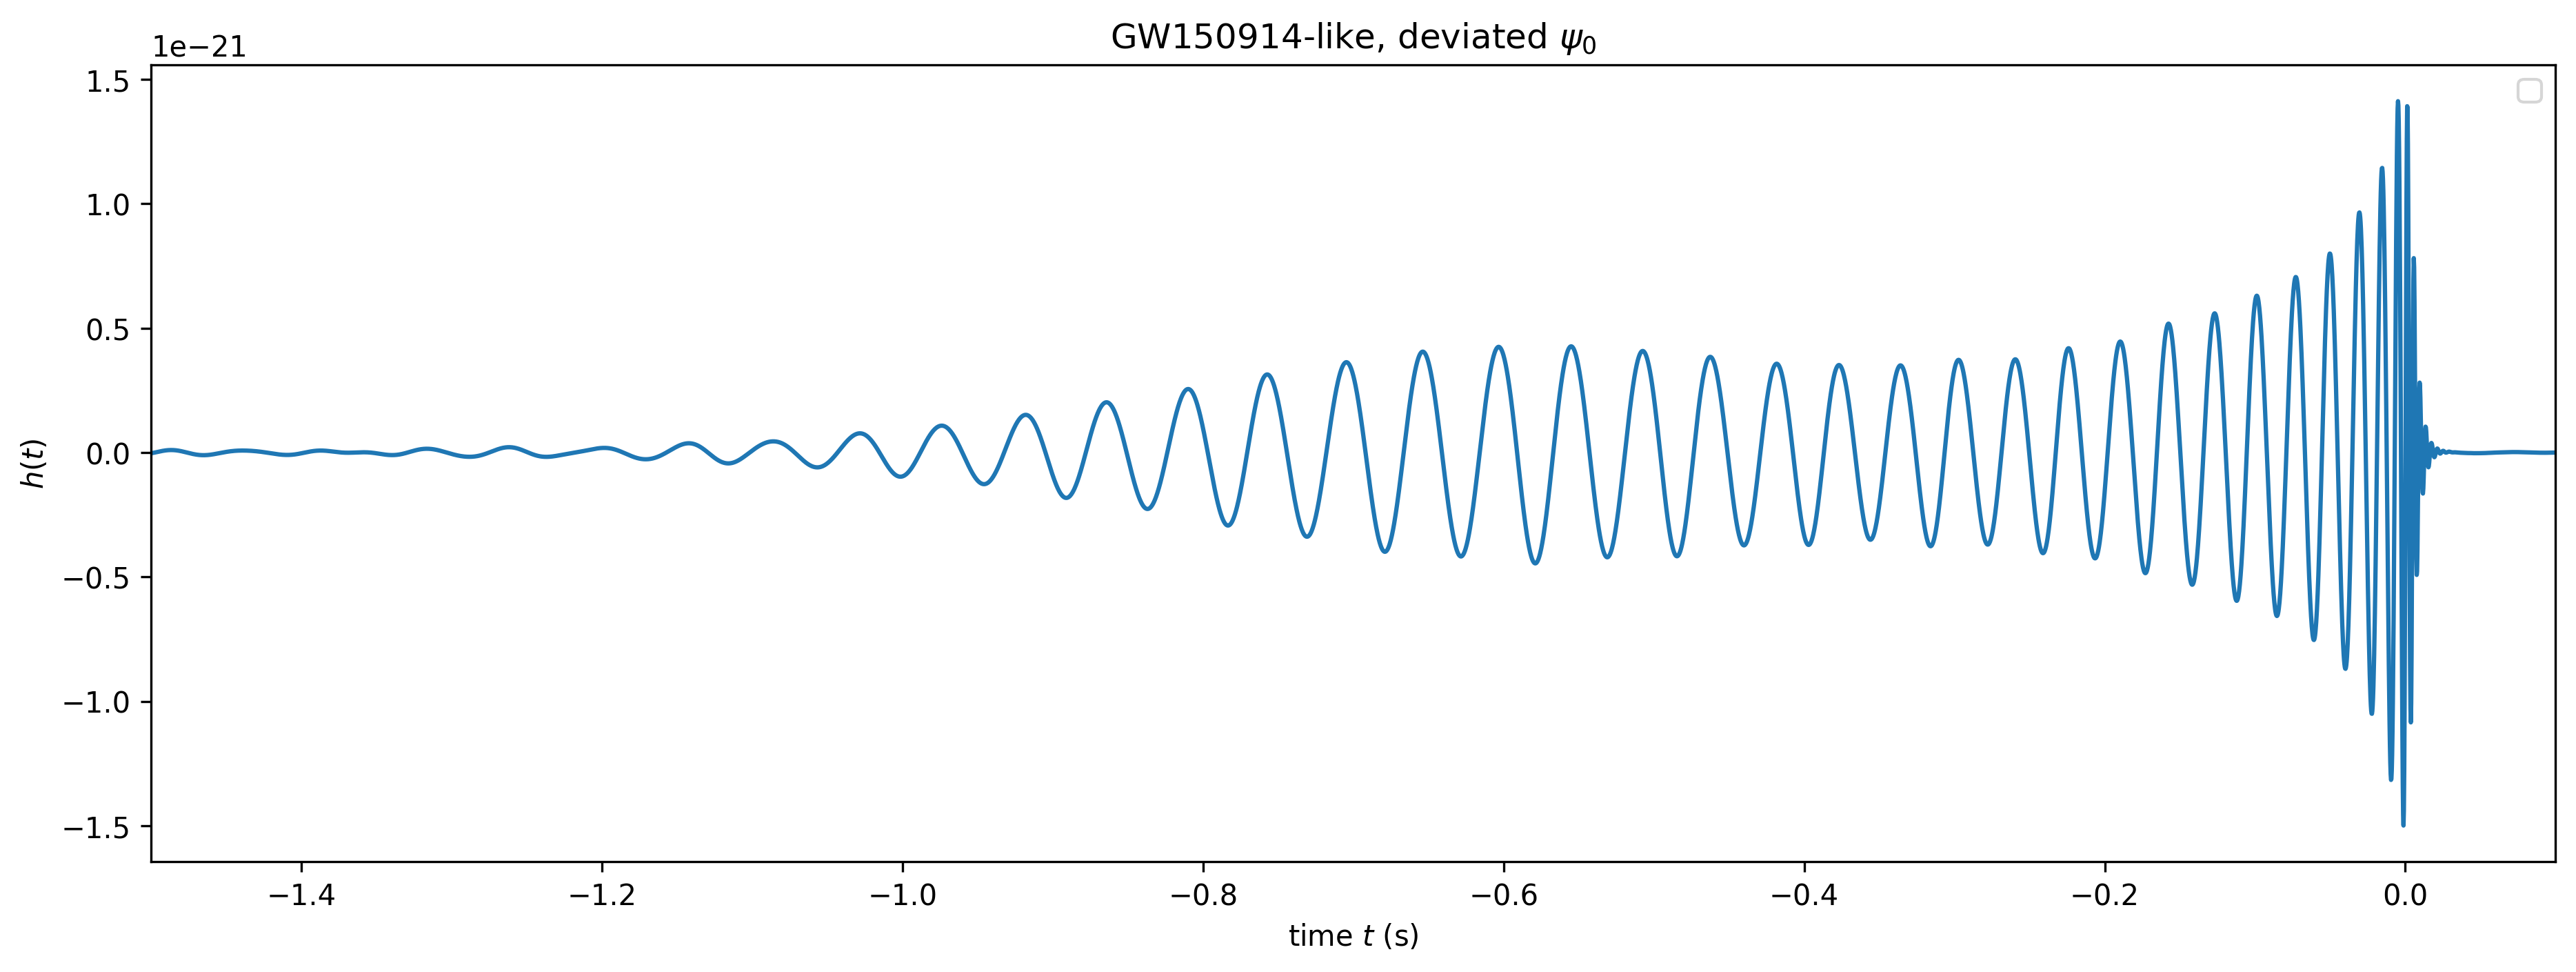

In [47]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
GW50914_ht_official = pd.read_csv("./GW150914_td.csv")
ts_official, ht_official = GW50914_ht_official["Time (s)"], GW50914_ht_official["Strain / 1e-21"]*1e-21
pp.plot(ts_official, ht_official)
pp.xlim([-0.9,0.1])
pp.xlim([-1.5,0.1])
pp.xlabel("time $t$ $($s$)$")
pp.ylabel("$h(t)$")
pp.legend()
pp.title("GW150914-like, deviated $\\psi_0$")

In [48]:
# from matplotlib.colors import LinearSegmentedColormap
# import pycbc.detector as detector
# ts = detector.Detector("H1").project_wave((hphc["0"][0][0]*np.exp(10*1j)).to_timeseries(delta_t=1/4096),
#                                      (hphc["0"][0][1]*np.exp(10*1j)).to_timeseries(delta_t=1/4096),
#                                      ra=2.321208458632003,
#                                      dec=-1.1482716840472416,
#                                      polarization=np.pi/6).sample_times
# mask = (1 < np.array(ts))


# gradient_colors = [
#     (0.0, (0, 0, 1)),    # 纯蓝（起始）
#     (0.5, (0.5, 0, 0.5)), # 紫色（中间）
#     (1.0, (1, 0, 0))     # 纯红（结束）
# ]
# cmap = LinearSegmentedColormap.from_list('blue_to_red', gradient_colors, N=11)
# delta_count = len(deltas)

# # 3. 创建共享X轴的两张子图（2行1列）
# pp.figure(
#     figsize=(15,5),  # 高度调整为8以容纳两个子图
#     dpi=300, 
# )
# import pycbc.types as tps

# # ts, _ = manual_fd_to_td(hphc["0"][2][0].data,hphc["0"][2][0].sample_frequencies.data, events["f_final"])

# # -------------------------- 第一张图（上） --------------------------
# # for i in range(len(deltas)):
# # for i in [1,2,4]:
# for i in [2]:
#     # i = 4
#     hhp_td = hphc["0"][i][0].to_timeseries(delta_t=1/4096)
#     hhp_ts = hhp_td.sample_times
#     hhc_td = hphc["0"][i][1].to_timeseries(delta_t=1/4096)
#     hhc_ts = hhc_td.sample_times
#     # w = detector.Detector("H1").project_wave(tps.TimeSeries(hhc_td, delta_t=hhp_ts[1]-hhp_ts[0]),
#     #                                 tps.TimeSeries(hhp_td, delta_t=hhc_ts[1]-hhc_ts[0]),
#     #                                 ra=2.321208458632003,
#     #                                 dec=-1.1482716840472416,
#     #                                 polarization=np.pi/6)
    
#     w = manual_project_ground_detector(hhc_td.data,
#                                     hhp_td.data,
#                                     ra=2.321208458632003,
#                                     dec=-1.1482716840472416,
#                                     polarization=np.pi/3)
#     # w = np.concatenate([w[(63.9 <= hhp_ts) & (hhp_ts < 64)], w[(0 <= hhp_ts) & (hhp_ts < 0.1)]])
#     # w = np.concatenate([w[len(hhp_ts)//20*18:], w[:len(hhp_ts)//50]])
#     # ts = np.concatenate([ts[len(hhp_ts)//20*18:], ts[:len(hhp_ts)//50]])
#     w = np.roll(w, -np.argmin(hhp_ts))
#     ts = np.roll(hhp_ts, -np.argmin(hhp_ts))
#     # if i == 1:
#     #     ts -= 64.0
    
#     sp = len(hhp_ts)//20*18
#     ep = len(hhp_ts)//50
#     step = np.diff(ts)[0]
#     w = np.concatenate([w[sp:], w[:ep]])
#     ts = np.array([ts[sp] + i * step for i in range(len(w))])
    
#     index_max = np.argmax(np.abs(w))
#     ts = ts - ts[index_max]
    
#     # ts -= ts[np.argmax(np.abs(w))]
    
#     if i == len(deltas)//2:
#         pp.plot(ts,w, label=f"$\\delta=${deltas[i]}",
#         color="black",
#         linewidth=0.5,
#         # linestyle="--"
#         )
#         continue
#     # 计算颜色
#     color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)
#     pp.plot(ts,w, label=f"$\\delta=${deltas[i]}",
#             color=color,
#             linewidth=0.5)

# pp.xlim([-0.9,0.1])
# pp.xlabel("time $t$ $($s$)$")
# pp.ylabel("$h(t)$")
# pp.legend()
# pp.title("GW150914-like, deviated $\\psi_0$")

In [49]:
from pycbc.waveform import utils as wfutils
from pycbc.filter import highpass

hp_gr_fd2td = wfutils.fd_to_td(hp_gr,1/4096,
                               left_window=(19.5,20),
                               left_beta=8
                               )
hp_gr_my_fd2td = highpass(wfutils.fd_to_td(hp_gr_my,1/4096,
                               left_window=(19.8,20),
                               left_beta=8
                               ), frequency=20)
hc_gr_my_fd2td = highpass(wfutils.fd_to_td(hc_gr_my,1/4096,
                               left_window=(19.8,20),
                               left_beta=8
                               ), frequency=20)
hp_gr_XPHM_fd2td = wfutils.fd_to_td(hp_gr_XPHM,1/4096,
                               left_window=(17,20),
                              #  left_beta=8
                               )

# hp_gr_HM_fd2td = wfutils.fd_to_td(hp_gr_HM,1/4096,
#                                left_window=(19.5,20),
#                                left_beta=0.99
#                                )


(-1.5, 0.1)

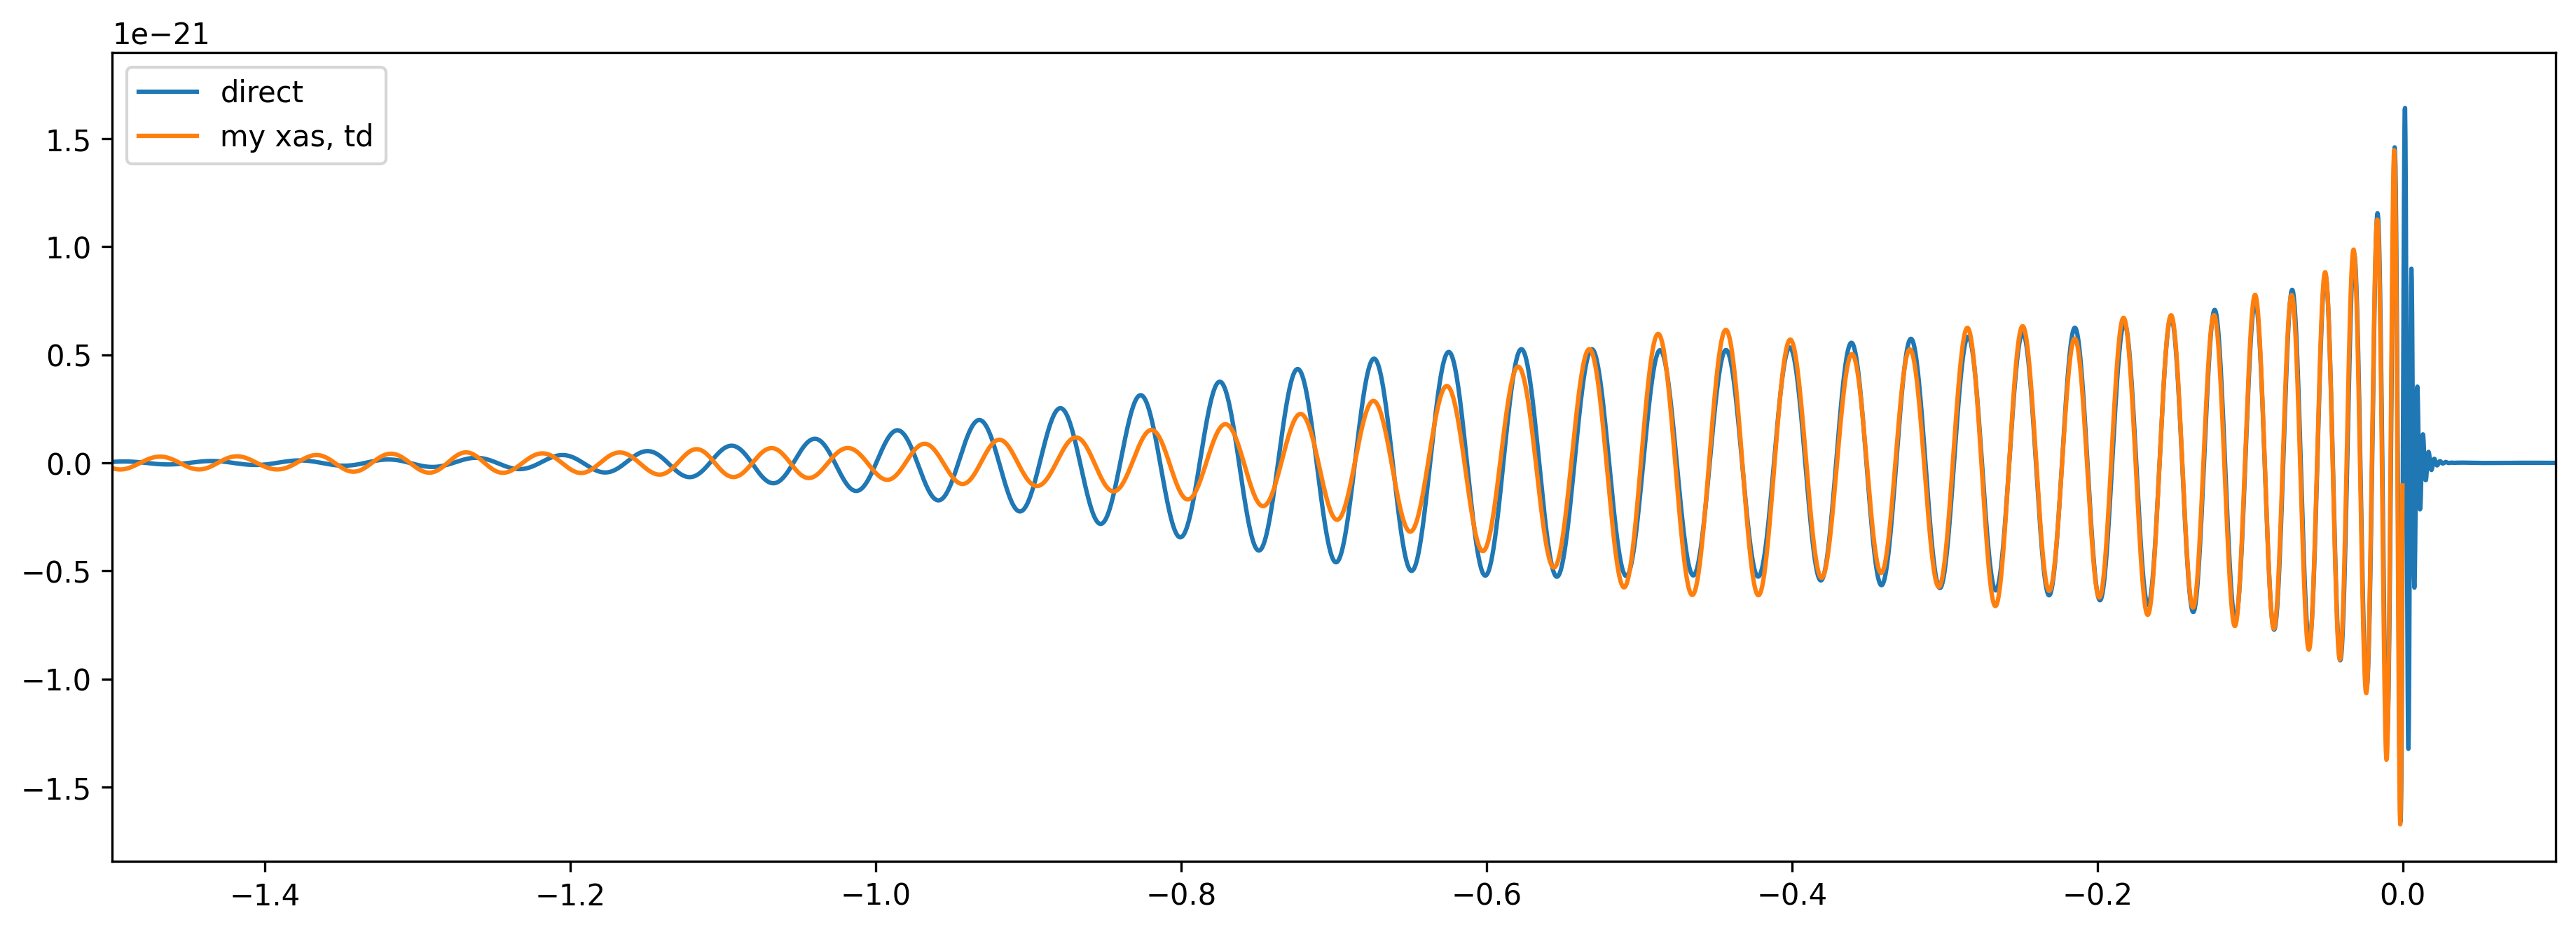

In [50]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
pp.plot(hp_gr_td.sample_times, hp_gr_td, label="direct")
# pp.plot(hp_gr_my_fd2td.sample_times, hp_gr_my_fd2td, label="my xas, td")
pp.plot(hp_gr_XPHM_fd2td.sample_times, hp_gr_XPHM_fd2td, label="my xas, td")
pp.legend()
pp.xlim([-1.5,0.1])
# pp.xlim([-16.1,-15.8])

In [51]:
# hp_gr_td2fd = hp_gr_td.to_frequencyseries(delta_f=1/16)

===== 进入 _lalsim_td_waveform，生成 IMRPhenomXAS 原生时域波形 =====
近似式： IMRPhenomXAS


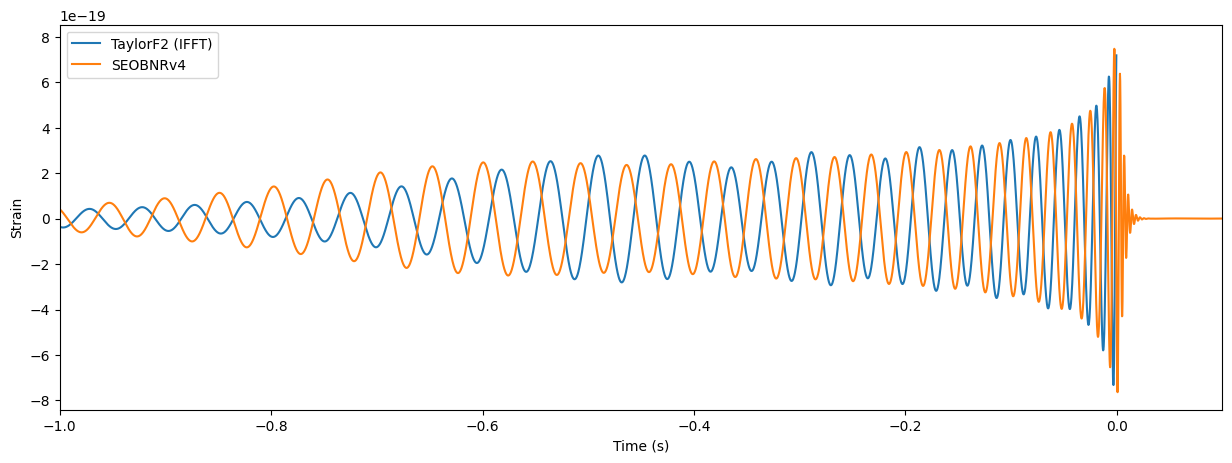

In [52]:
import matplotlib.pyplot as pp
from pycbc import types, fft, waveform

pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=100, 
)
# # Get a time domain waveform
# hp, hc = waveform.get_td_waveform(approximant='SEOBNRv4',
#                              mass1=6, mass2=6, delta_t=1.0/4096, f_lower=40)

# # Get a frequency domain waveform
# sptilde, sctilde = waveform. get_fd_waveform(approximant="TaylorF2",
#                              mass1=6, mass2=6, delta_f=1.0/4, f_lower=40)

# Get a time domain waveform
hp, hc = waveform.get_td_waveform(approximant='IMRPhenomXAS',
                             mass1=37, mass2=29, delta_t=1.0/4096, f_lower=20)

# Get a frequency domain waveform
sptilde, sctilde = waveform. get_fd_waveform(approximant="IMRPhenomXAS",
                             mass1=37, mass2=29, delta_f=1.0/4, f_lower=20)

# FFT it to the time-domain
tlen = int(1.0 / hp.delta_t / sptilde.delta_f)
sptilde.resize(tlen//2 + 1)
sp = types.TimeSeries(types.zeros(tlen), delta_t=hp.delta_t)
fft.ifft(sptilde, sp)

pp.plot(sp.sample_times, sp, label="TaylorF2 (IFFT)")
pp.plot(hp.sample_times, hp, label='SEOBNRv4')

pp.ylabel('Strain')
pp.xlabel('Time (s)')
pp.legend()
pp.xlim([-1.,0.1])
pp.show()

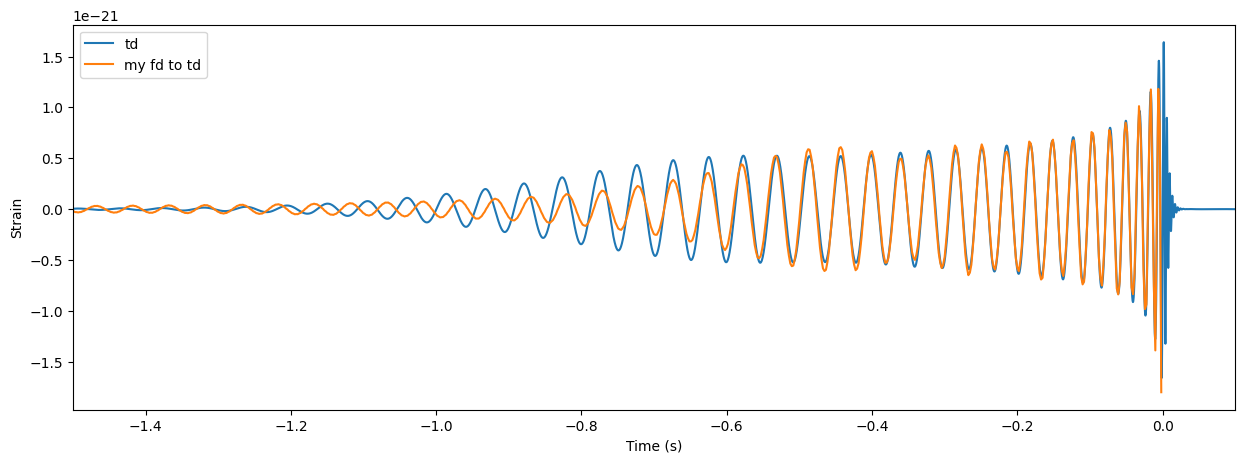

In [53]:

import matplotlib.pyplot as pp
from pycbc import types, fft, waveform

pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=100, 
)
sptilde = hp_gr_my.copy()
# FFT it to the time-domain
tlen = int(1.0 / hp_gr_td.delta_t / hp_gr_td.delta_f)
sptilde.resize(tlen//2 + 1)
sp = types.TimeSeries(types.zeros(tlen), delta_t=hp_gr_td.delta_t)
fft.ifft(sptilde, sp)

pp.plot(hp_gr_td.sample_times, hp_gr_td, label='td')
pp.plot(sp.sample_times, sp, label="my fd to td")

pp.ylabel('Strain')
pp.xlabel('Time (s)')
pp.legend()
pp.xlim([-1.5,0.1])
pp.show()

In [54]:
sptilde.res

AttributeError: 'FrequencySeries' object has no attribute 'res'

In [ ]:
int(1.0 / hp_gr_td.delta_t / hp_gr_td.delta_f)

6792

(-16.1, -15.9)

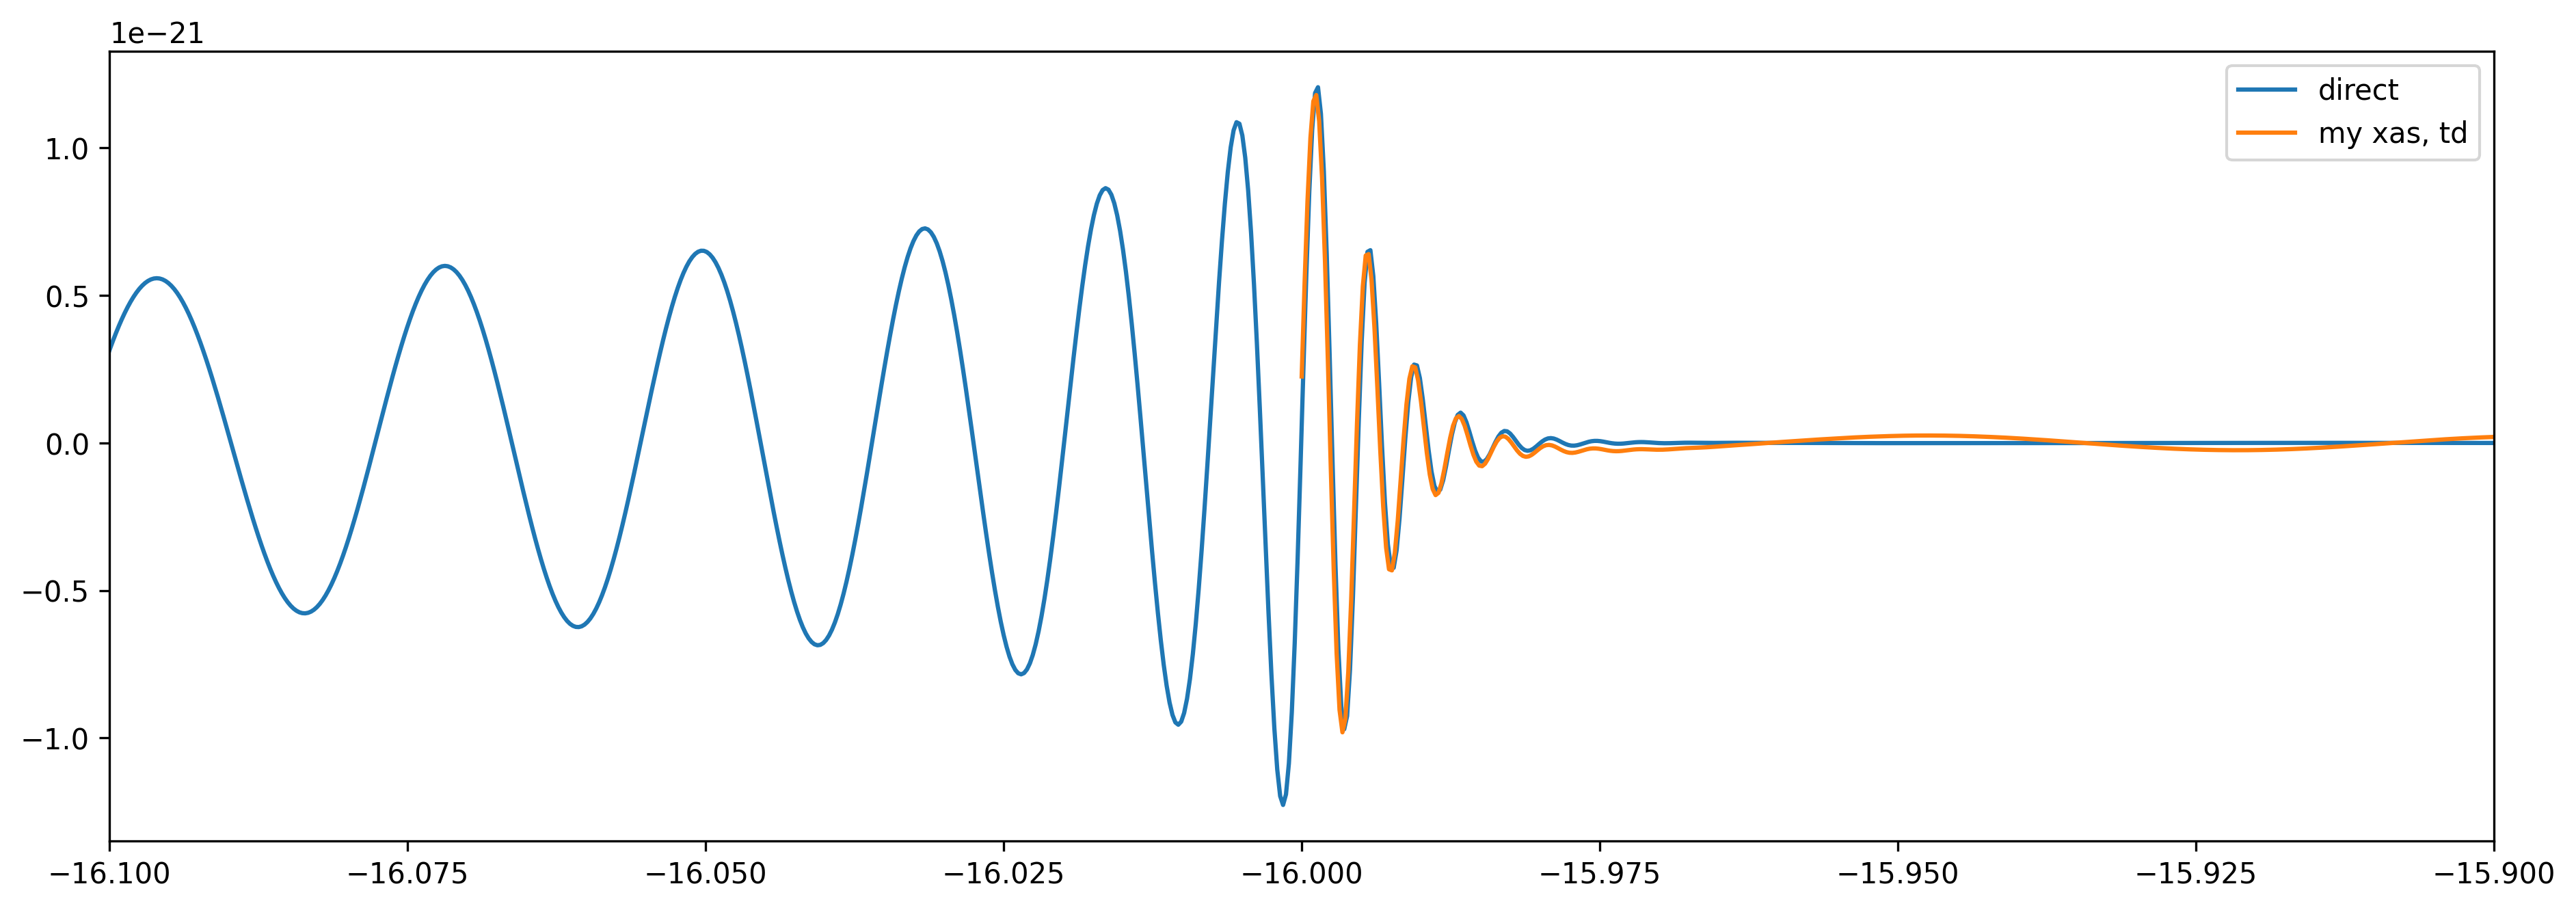

In [ ]:
pp.figure(
    figsize=(15,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)
pp.plot(hp_gr_td.sample_times-16-0.0125/2/2/2, hp_gr_td, label="direct")
pp.plot(hp_gr_my_fd2td.sample_times, hp_gr_my_fd2td, label="my xas, td")
pp.legend()
pp.xlim([-16.1,-15.9])

In [ ]:
1/(1/8/2/2/2/10)

640.0

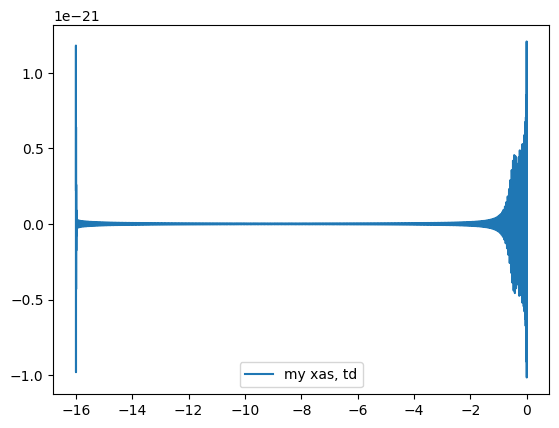

In [ ]:
pp.plot(hp_gr_my_fd2td.sample_times, hp_gr_my_fd2td, label="my xas, td")
pp.legend()
# pp.xlim([-1.5,0.1])

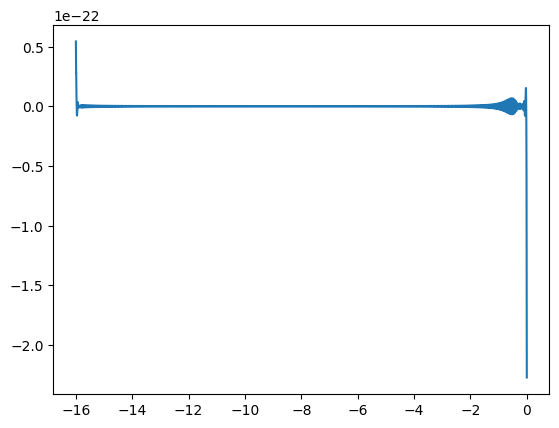

In [ ]:
pp.plot(hp_gr_fd2td.sample_times, hp_gr_fd2td-hp_gr_my_fd2td)

In [ ]:
hp_gr.data

array([0.-0.j, 0.-0.j, 0.-0.j, ..., 0.-0.j, 0.-0.j, 0.-0.j])

时间轴长度：65536，h(t)长度：65536
h(t)峰值应变：1.17e-21


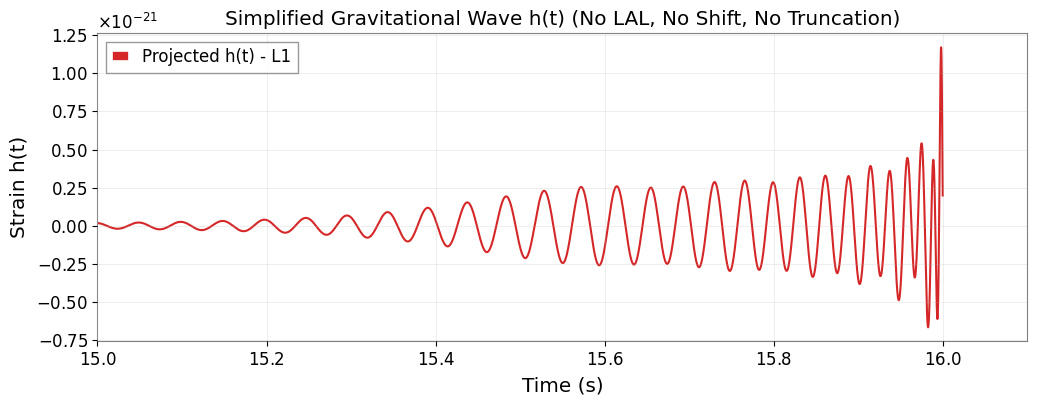

In [ ]:
import numpy as np
import warnings
import astropy.units as u
from gwpy.timeseries import TimeSeries
from gwpy.frequencyseries import FrequencySeries

# 忽略无关警告
warnings.filterwarnings("ignore")

# -------------------------- 1. 核心简化函数：频域hp/hc → 时域h(t) --------------------------
def fd2td_and_project(hp_fd, hc_fd, dt, original_f_min, 
                      ra=1.95, dec=-1.22, polarization=0.3, detector="H1"):
    """
    极简版：频域引力波极化 → 时域极化 → 投影到地基探测器，输出h(t)
    （无LAL、无平移、无截断，仅保留核心转换+投影）
    
    参数：
        hp_fd (gwpy.frequencyseries.FrequencySeries): 频域加号极化波形
        hc_fd (gwpy.frequencyseries.FrequencySeries): 频域交叉极化波形
        dt (float): 采样间隔（秒，如1/4096）
        original_f_min (float): 原始起始频率（Hz，用于高通滤波去噪）
        ra (float, 可选): 波源赤经（rad），默认GW150914参数
        dec (float, 可选): 波源赤纬（rad），默认GW150914参数
        polarization (float, 可选): 引力波偏振角（rad），默认0.3
        detector (str, 可选): 探测器名称（H1/L1/V1），默认"H1"
    
    返回：
        t (np.ndarray): 时域波形时间轴（秒）
        h_proj (np.ndarray): 投影到探测器的时域应变h(t)
        hpt_td (np.ndarray): 时域加号极化（numpy数组，可选）
        hct_td (np.ndarray): 时域交叉极化（numpy数组，可选）
    """
    # ======================== 步骤1：频域 → 时域（核心IFFT+幅度校正） ========================
    # 逆傅里叶变换（频域→时域）
    hpt = hp_fd.ifft()
    hct = hc_fd.ifft()
    
    # 幅度校正（必须！修正GWpy IFFT默认缩放，保证物理幅度正确，不改变波形形状）
    hpt *= 2 * hp_fd.df.value
    hct *= 2 * hp_fd.df.value
    
    # ======================== 步骤2：高通滤波（去低频噪声，不改变有效波形形状） ========================
    # 手动实现高通滤波（替代原cond模块，无额外依赖，8阶巴特沃斯滤波器）
    from scipy.signal import butter, filtfilt
    def high_pass(signal, dt, f_min, order=8):
        fs = 1 / dt
        nyq = 0.5 * fs
        high = f_min / nyq
        b, a = butter(order, high, btype='high', analog=False)
        return filtfilt(b, a, signal)  # 零相位滤波，不改变波形相位/形状
    
    hpt_td = high_pass(hpt.value, dt, original_f_min)
    hct_td = high_pass(hct.value, dt, original_f_min)
    
    # 生成时间轴
    t = np.arange(len(hpt_td)) * dt
    
    # ======================== 步骤3：投影到地基探测器（复用你的手动投影逻辑） ========================
    def manual_project(hp, hc, ra, dec, polarization, detector):
        # 探测器几何参数（纬度rad，臂1方位角rad，臂2方位角rad）
        detector_params = {
            "H1": (0.8108, 2.0944, 5.2360),   # Hanford
            "L1": (0.5334, 4.2761, 5.8476),   # Livingston
            "V1": (0.7616, 0.0, 1.5708)       # Virgo
        }
        lat_det, phi1, phi2 = detector_params[detector]
        
        # 计算天线响应函数F+、F×
        gst = 0.0
        h = gst - ra
        cos_z = np.sin(dec) * np.sin(lat_det) + np.cos(dec) * np.cos(lat_det) * np.cos(h)
        cos_z = np.clip(cos_z, -1.0, 1.0)
        z = np.arccos(cos_z)
        sin_z = np.sin(z)
        
        if np.isclose(sin_z, 0):
            A = 0.0
        else:
            sin_A = -np.cos(dec) * np.sin(h) / sin_z
            cos_A = (np.sin(dec) - sin_z * np.sin(lat_det)) / (cos_z * np.cos(lat_det))
            A = np.arctan2(sin_A, cos_A)
        
        F1 = 0.5 * (np.cos(2*phi1) * (1 + cos_z**2) + np.sin(2*phi1) * cos_z)
        F2 = 0.5 * (np.cos(2*phi2) * (1 + cos_z**2) + np.sin(2*phi2) * cos_z)
        psi = polarization
        F_plus = 0.5 * (F1 - F2) * np.cos(2*psi) - 0.5 * (F1 + F2) * np.sin(2*psi)
        F_cross = 0.5 * (F1 - F2) * np.sin(2*psi) + 0.5 * (F1 + F2) * np.cos(2*psi)
        
        return F_plus * hp + F_cross * hc
    
    # 计算投影后的h(t)
    h_proj = manual_project(hpt_td, hct_td, ra, dec, polarization, detector)
    
    return t, h_proj, hpt_td, hct_td

# -------------------------- 2. 使用示例 --------------------------
if __name__ == "__main__":
    # 生成模拟频域波形（替换为你的真实hp_fd/hc_fd）
    # 参数：4096Hz采样率，20Hz起始频率，36+29太阳质量双黑洞
    fs = 4096
    dt = 1 / fs
    f_min = 20.0
    f_max = fs / 2
    df = 1/16  # 频率分辨率
    
    # 模拟频域hp/hc（高斯包络调制的正弦波，仅作示例）
    freqs = hp_gr.sample_frequencies
    hp_fd_data = hp_gr.data
    hc_fd_data = hc_gr.data
    
    # 转为GWpy FrequencySeries
    hp_fd = FrequencySeries(hp_fd_data, df=df, f0=f_min)
    hc_fd = FrequencySeries(hc_fd_data, df=df, f0=f_min)
    
    # 调用简化函数，投影到L1探测器
    t, h_proj, hpt, hct = fd2td_and_project(
        hp_fd=hp_fd,
        hc_fd=hc_fd,
        dt=dt,
        original_f_min=f_min,
        detector="L1"  # 可改H1/V1
    )
    
    # 输出结果
    print(f"时间轴长度：{len(t)}，h(t)长度：{len(h_proj)}")
    print(f"h(t)峰值应变：{np.max(np.abs(h_proj)):.2e}")
    
    # 绘图（可选，需安装matplotlib）
    import matplotlib.pyplot as plt
    plt.figure(figsize=(12, 4))
    plt.plot(t, h_proj, label=f'Projected h(t) - L1', color='tab:red')
    plt.xlabel('Time (s)')
    plt.ylabel('Strain h(t)')
    plt.title('Simplified Gravitational Wave h(t) (No LAL, No Shift, No Truncation)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    pp.xlim([30,33])
    pp.xlim([15.,16.1])
    plt.show()

In [ ]:
def get_fPhaseMatchIN(mass1, mass2, spin1z, spin2z) :
    M = mass1+mass2
    eta = cvs.eta_from_mass1_mass2(mass1, mass2)
    eta2 = eta*eta # These can speed up a bit, we call them multiple times
    chi1, chi2 = spin1z, spin2z
    Seta = np.sqrt(1.0 - 4.0*eta)
    # These are m1/Mtot and m2/Mtot
    m1ByM = 0.5 * (1.0 + Seta)
    m2ByM = 0.5 * (1.0 - Seta)
    m1ByMSq = m1ByM*m1ByM
    m2ByMSq = m2ByM*m2ByM
    # PN symmetry coefficient
    totchi = ((m1ByMSq * chi1 + m2ByMSq * chi2) / (m1ByMSq + m2ByMSq))
    totchi2 = totchi*totchi
    dchi = chi1-chi2
    # Normalised PN reduced spin parameter
    chi_eff = (m1ByM*chi1 + m2ByM*chi2)
    chiPN   = (chi_eff - (38./113.)*eta*(chi1 + chi2)) / (1. - (76.*eta/113.))
    chiPN2  = chiPN*chiPN

    # Compute final spin and radiated energy
    aeff   = (((3.4641016151377544*eta + 20.0830030082033*eta2 - 12.333573402277912*eta2*eta)/(1 + 7.2388440419467335*eta)) + ((m1ByMSq + m2ByMSq)*totchi + ((-0.8561951310209386*eta - 0.09939065676370885*eta2 + 1.668810429851045*eta2*eta)*totchi + (0.5881660363307388*eta - 2.149269067519131*eta2 + 3.4768263932898678*eta2*eta)*totchi2 + (0.142443244743048*eta - 0.9598353840147513*eta2 + 1.9595643107593743*eta2*eta)*totchi2*totchi) / (1 + (-0.9142232693081653 + 2.3191363426522633*eta - 9.710576749140989*eta2*eta)*totchi)) + (0.3223660562764661*dchi*Seta*(1 + 9.332575956437443*eta)*eta2 - 0.059808322561702126*dchi*dchi*eta2*eta + 2.3170397514509933*dchi*Seta*(1 - 3.2624649875884852*eta)*eta2*eta*totchi))
    Erad   = ((((0.057190958417936644*eta + 0.5609904135313374*eta2 - 0.84667563764404*eta2*eta + 3.145145224278187*eta2*eta2)*(1. + (-0.13084389181783257 - 1.1387311580238488*eta + 5.49074464410971*eta2)*totchi + (-0.17762802148331427 + 2.176667900182948*eta2)*totchi2 + (-0.6320191645391563 + 4.952698546796005*eta - 10.023747993978121*eta2)*totchi*totchi2)) / (1. + (-0.9919475346968611 + 0.367620218664352*eta + 4.274567337924067*eta2)*totchi)) + (- 0.09803730445895877*dchi*Seta*(1. - 3.2283713377939134*eta)*eta2 + 0.01118530335431078*dchi*dchi*eta2*eta - 0.01978238971523653*dchi*Seta*(1. - 4.91667749015812*eta)*eta*totchi))
    # Compute ringdown and damping frequencies from fits
    fring = ((0.05947169566573468 - 0.14989771215394762*aeff + 0.09535606290986028*aeff*aeff + 0.02260924869042963*aeff*aeff*aeff - 0.02501704155363241*aeff*aeff*aeff*aeff - 0.005852438240997211*(aeff**5) + 0.0027489038393367993*(aeff**6) + 0.0005821983163192694*(aeff**7))/(1 - 2.8570126619966296*aeff + 2.373335413978394*aeff*aeff - 0.6036964688511505*aeff*aeff*aeff*aeff + 0.0873798215084077*(aeff**6)))/(1. - Erad)
    
    # Fitting function for hybrid minimum energy circular orbit (MECO) function and computation of ISCO frequency
    Z1tmp = 1. + np.cbrt((1. - aeff*aeff) ) * (np.cbrt(1. + aeff) + np.cbrt(1. - aeff))
    Z1tmp = np.where(Z1tmp>3., 3., Z1tmp)
    Z2tmp = np.sqrt(3.*aeff*aeff + Z1tmp*Z1tmp)
    fISCO  = (1. / ((3. + Z2tmp - np.sign(aeff)*np.sqrt((3. - Z1tmp) * (3. + Z1tmp + 2.*Z2tmp)))**(3./2.) + aeff))/np.pi
    
    fMECO    = (((0.018744340279608845 + 0.0077903147004616865*eta + 0.003940354686136861*eta2 - 0.00006693930988501673*eta2*eta)/(1. - 0.10423384680638834*eta)) + ((chiPN*(0.00027180386951683135 - 0.00002585252361022052*chiPN + eta2*eta2*(-0.0006807631931297156 + 0.022386313074011715*chiPN - 0.0230825153005985*chiPN2) + eta2*(0.00036556167661117023 - 0.000010021140796150737*chiPN - 0.00038216081981505285*chiPN2) + eta*(0.00024422562796266645 - 0.00001049013062611254*chiPN - 0.00035182990586857726*chiPN2) + eta2*eta*(-0.0005418851224505745 + 0.000030679548774047616*chiPN + 4.038390455349854e-6*chiPN2) - 0.00007547517256664526*chiPN2))/(0.026666543809890402 + (-0.014590539285641243 - 0.012429476486138982*eta + 1.4861197211952053*eta2*eta2 + 0.025066696514373803*eta2 + 0.005146809717492324*eta2*eta)*chiPN + (-0.0058684526275074025 - 0.02876774751921441*eta - 2.551566872093786*eta2*eta2 - 0.019641378027236502*eta2 - 0.001956646166089053*eta2*eta)*chiPN2 + (0.003507640638496499 + 0.014176504653145768*eta + 1.*eta2*eta2 + 0.012622225233586283*eta2 - 0.00767768214056772*eta2*eta)*chiPN2*chiPN)) + (dchi*dchi*(0.00034375176678815234 + 0.000016343732281057392*eta)*eta2 + dchi*Seta*eta*(0.08064665214195679*eta2 + eta*(-0.028476219509487793 - 0.005746537021035632*chiPN) - 0.0011713735642446144*chiPN)))
    
    fIMmatch = 0.6 * (0.5 * fring + fISCO)
    fINmatch = fMECO
    deltaf   = (fIMmatch - fINmatch) * 0.03
    
    fPhaseMatchIN  = fINmatch - 1.0*deltaf
    timeMetric = 4.925491025543575903411922162094833998e-6 * M
    return fPhaseMatchIN/timeMetric

fPhaseMatchIN = get_fPhaseMatchIN(events['mass1'], events['mass2'], events['spin1z'], events['spin2z'])

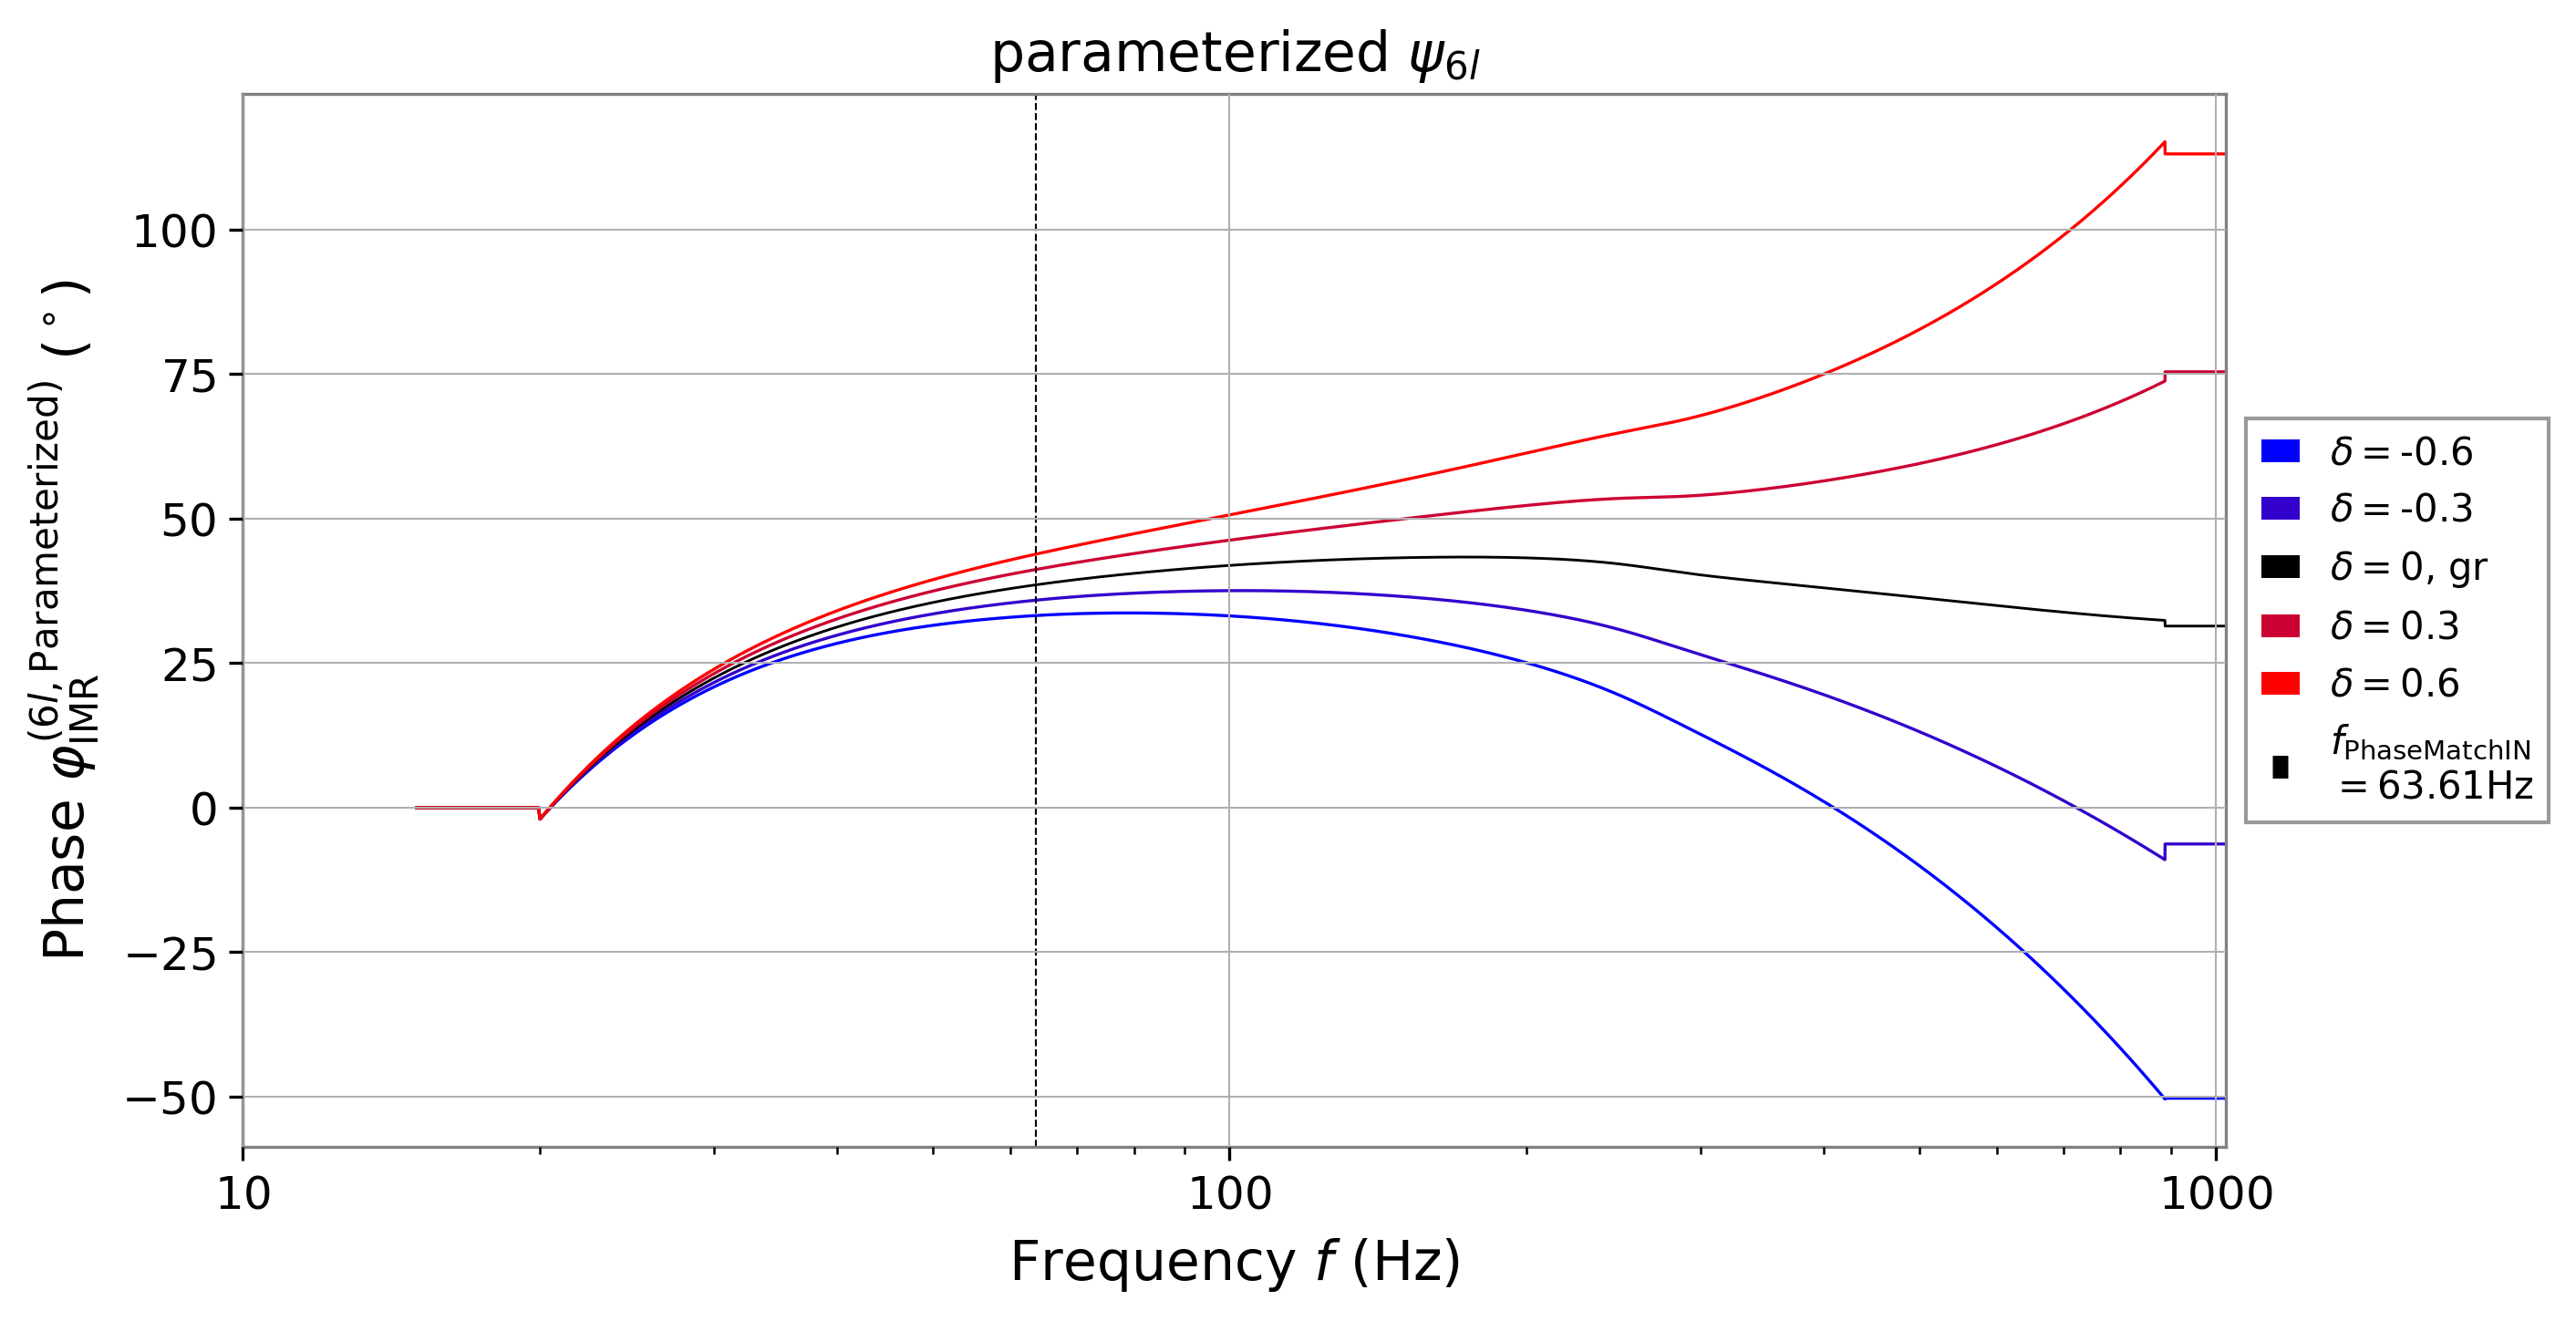

In [ ]:
import numpy as np
import matplotlib.pyplot as pp
from matplotlib.colors import LinearSegmentedColormap

# -------------------------- 通用参数定义（请确保这些变量已提前定义） --------------------------
# 示例占位（请替换为你的实际数据）
# hphc = 你的hphc数据结构
# hp_gr = 你的hp_gr数据结构
# deltas = 你的delta列表（如[0.1, 0.2, 0.3]）
# fPhaseMatchIN = 相位匹配频率（如100.5）
# -------------------------------------------------------------------------------------------

# 1. 定义通用参数
order = "6l"
start_index = 15 * 16
end_index = len(hphc[order][0][0].data)  # 统一end_index

# 2. 定义渐变颜色映射（仅需定义一次）
gradient_colors = [
    (0.0, (0, 0, 1)),    # 纯蓝（起始）
    (0.5, (0.5, 0, 0.5)), # 紫色（中间）
    (1.0, (1, 0, 0))     # 纯红（结束）
]
cmap = LinearSegmentedColormap.from_list('blue_to_red', gradient_colors, N=11)
delta_count = len(deltas)

# 3. 创建共享X轴的两张子图（2行1列）
pp.figure(
    figsize=(10,5),  # 高度调整为8以容纳两个子图
    dpi=300, 
)

# -------------------------- 第一张图（上） --------------------------
for i in range(len(deltas)):
    # # 数据修正
    # hphc[order][i][0][:15*16] = hphc[order][i][0][15*16]
    # 计算颜色
    color = cmap(i / (delta_count - 1) if delta_count > 1 else 0)
    # 绘制相位曲线
    if i == len(deltas)//2:
        pp.plot(
            hp_gr.sample_frequencies[start_index:end_index],
            np.unwrap(np.angle(hphc[order][i][0].data))[start_index:],
            color="black",
            label=f"$\\delta=${deltas[i]}, gr",
            linewidth=0.7
        )
        continue
    pp.plot(
        hp_gr.sample_frequencies[start_index:end_index],
        np.unwrap(np.angle(hphc[order][i][0].data))[start_index:],
        color=color,
        label=f"$\\delta=${deltas[i]}",
        linewidth=0.8
    )

# -------------------------- 共用元素：垂直虚线 + 图例 --------------------------
# 绘制垂直虚线（因共享X轴，画在ax1上即可显示在两个子图中）
dashed_line = pp.axvline(
    x=fPhaseMatchIN, 
    color='k', 
    linestyle='--', 
    linewidth=0.5
)

pp.xscale("log")

pp.xlabel("Frequency $f$ (Hz)")
pp.ylabel(f"Phase $\\varphi_\\text{{IMR}}^{{({order},\\text{{Parameterized}})}}$ $(^\circ)$")
# -------------------------- 核心修改：将图例放到图外右侧 --------------------------
# 1. 先获取曲线的图例句柄和标签
handles, labels = pp.gca().get_legend_handles_labels()  # gca()获取当前轴实例
# 2. 添加垂直虚线到图例中（可选，若需要显示虚线说明）
handles.append(dashed_line)
labels.append(f"$f_\\text{{PhaseMatchIN}}$"+"\n"+f"$=${fPhaseMatchIN:.2f}Hz")
# 3. 配置图例外置参数
pp.legend(
    handles=handles,  # 传入包含曲线和虚线的句柄
    labels=labels,    # 传入对应标签
    loc='center left',        # 图例的左中对齐锚点
    bbox_to_anchor=(1.01, 0.5),# 锚点定位：x=1.0（图像右边缘），y=0.5（图像垂直中心）
    frameon=True,             # 显示图例边框
    fontsize=10,              # 图例字体大小
    borderaxespad=0.0         # 取消图例与锚点的额外间距
)

# -------------------------- 布局优化：留出右侧空间给图例 --------------------------
pp.subplots_adjust(right=0.85)  # 右侧留出15%空间（0.85表示图像占85%宽度，剩余给图例）
# 移除无用的hspace参数（单图无需上下子图间距）

pp.title(f"parameterized $\\psi_{{{order}}}$")

pp.xlim([10,1024])

pp.savefig(f"/workspace/chendawww/server/modify_WF4Py/figs/parameterized_phasing/GW150914_like_phasing_{order}.pdf", bbox_inches='tight', dpi=500)

In [ ]:
import numpy as np
from itertools import product  # 导入product函数

from pycbc.filter import match
from pycbc.psd import aLIGOZeroDetHighPower


psd = aLIGOZeroDetHighPower(len(hp_gr.sample_frequencies.data), events["delta_f"], 0)


print(f"length pycbc: {len(hp_gr)}")
print(f"length my: {len(hp_gr_my)}")
mp, _ = match(hp_gr[:len(hp_gr_my)], hp_gr_my, psd=psd[:len(hp_gr_my)], low_frequency_cutoff=events["f_lower"])
print('The hp match is: {:.20f}'.format(mp))
mc, _ = match(hc_gr[:len(hp_gr_my)], hc_gr_my, psd=psd[:len(hp_gr_my)], low_frequency_cutoff=events["f_lower"])
print('The hc match is: {:.20f}'.format(mc))

length pycbc: 32769
length my: 32769
The hp match is: 0.99999587750995200253
The hc match is: 0.99999587750995222457


In [ ]:
# import numpy as np
# from itertools import product  # 导入product函数

# num = 5
# mass1_s = np.linspace(3, 100, num)
# mass2_s = np.linspace(3, 100, num)
# spin1z_s = np.linspace(-0.99, 0.99, num)
# spin2z_s = np.linspace(-0.99, 0.99, num)


# from pycbc.filter import match
# from pycbc.psd import aLIGOZeroDetHighPower



# hp_matches = []
# hc_matches = []
# # product直接生成所有参数的笛卡尔积，一次遍历即可
# for params in product(mass1_s, mass2_s, spin1z_s, spin2z_s):
#     mass1, mass2, spin1z, spin2z = params  # 解包得到单组参数
#     # 循环体内处理参数（同方法1）
#     # print(f"mass1={mass1:.2f}, mass2={mass2:.2f}, spin1z={spin1z:.2f}, spin2z={spin2z:.2f}")

#     hp_gr, hc_gr = wf.get_fd_waveform(approximant='IMRPhenomXAS',
#                                                         mass1=mass1,
#                                                         mass2=mass2,
#                                                         spin1z=spin1z,
#                                                         spin2z=spin2z,
#                                                         delta_f=events["delta_f"],
#                                                         distance=events['distance'],
#                                                         # mode_array = [[2,-2]],
#                                                         # inclination=events['inclination'],
#                                                         # f_final=events['f_final'],
#                                                         f_lower=events["f_lower"],
#                                                         f_ref=events["f_ref"],
#                                                         )
#     psd = aLIGOZeroDetHighPower(len(hp_gr.sample_frequencies.data), events["delta_f"], 0)

#     hp_gr_my, hc_gr_my = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
#                                                         mass1=mass1,
#                                                         mass2=mass2,
#                                                         spin1z=spin1z,
#                                                         spin2z=spin2z,
#                                                         delta_f=events["delta_f"],
#                                                         distance=events['distance'],
#                                                         # mode_array = [[2,-2]],
#                                                         # inclination=events['inclination'],
#                                                         f_final=events['f_final'],
#                                                         f_lower=events["f_lower"],
#                                                         f_ref=events["f_ref"],
#                                                         )
    
#     print(f"length pycbc: {len(hp_gr)}")
#     print(f"length my: {len(hp_gr_my)}")
#     mp, _ = match(hp_gr, hp_gr_my, psd=psd, low_frequency_cutoff=events["f_lower"])
#     print('The hp match is: {:.20f}'.format(mp))
#     mc, _ = match(hc_gr, hc_gr_my, psd=psd, low_frequency_cutoff=events["f_lower"])
#     print('The hc match is: {:.20f}'.format(mc))
#     hp_matches.append(mp)
#     hc_matches.append(mc)

In [ ]:
hp_matches = np.array(hp_matches)

NameError: name 'hp_matches' is not defined

In [ ]:
(
    len(hp_matches[hp_matches > 1-1e-3]),
    len(hp_matches[hp_matches > 1-5e-4]),
    len(hp_matches[hp_matches > 1-7e-4]),
    len(hp_matches[hp_matches > 1-1e-4]),
    
    len(hp_matches[hp_matches > 1-1e-5]),
    len(hp_matches[hp_matches > 1-1e-6]),
    len(hp_matches[hp_matches > 1-1e-7]),
    len(hp_matches[hp_matches > 1-1e-8]),
    len(hp_matches[hp_matches > 1-1e-9]),
    len(hp_matches[hp_matches > 1-1e-10]),
    len(hp_matches[hp_matches > 1-1e-11]),
    len(hp_matches[hp_matches > 1-1e-12]),
    len(hp_matches[hp_matches > 1-1e-16]),
)


(625, 625, 625, 625, 526, 426, 389, 357, 344, 327, 321, 321, 199)

(array([  2.,   0.,   2.,   5.,   0.,   2.,   0.,   4.,  12.,   4.,   6.,
         10.,   4.,   6.,   3.,  11.,  10.,  19.,  18., 408.]),
 array([0.99999011, 0.9999906 , 0.9999911 , 0.99999159, 0.99999209,
        0.99999258, 0.99999308, 0.99999357, 0.99999406, 0.99999456,
        0.99999505, 0.99999555, 0.99999604, 0.99999654, 0.99999703,
        0.99999753, 0.99999802, 0.99999852, 0.99999901, 0.99999951,
        1.        ]),
 <BarContainer object of 20 artists>)

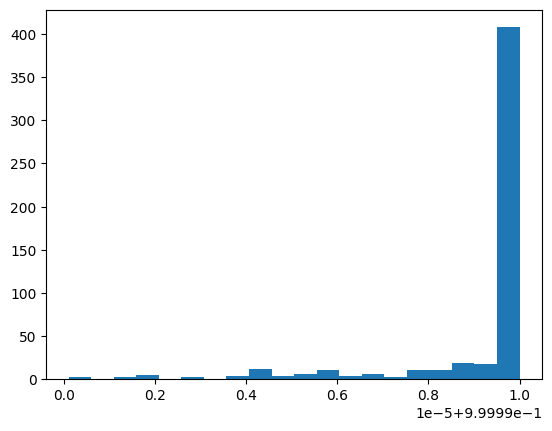

In [ ]:
pp.hist(hp_matches[hp_matches > 1-1e-5], bins=20)

(array([  8.,   0.,   2.,   0.,   4.,   6.,   2.,   0.,   6.,   8.,   6.,
          5.,   2.,   8.,  12.,   8.,  12.,  12.,  29., 495.]),
 array([0.99990124, 0.99990618, 0.99991112, 0.99991606, 0.99992099,
        0.99992593, 0.99993087, 0.99993581, 0.99994075, 0.99994568,
        0.99995062, 0.99995556, 0.9999605 , 0.99996543, 0.99997037,
        0.99997531, 0.99998025, 0.99998519, 0.99999012, 0.99999506,
        1.        ]),
 <BarContainer object of 20 artists>)

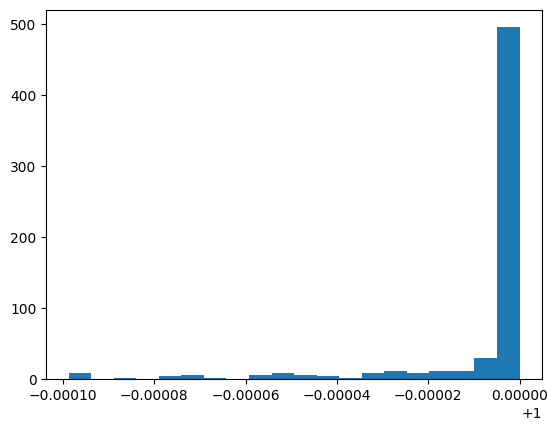

In [ ]:
pp.hist(hc_matches, bins=20)

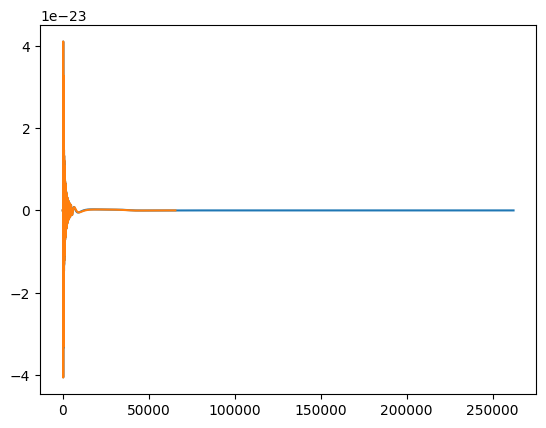

In [ ]:
pp.plot(hp_gr)
pp.plot(hp_gr_my)

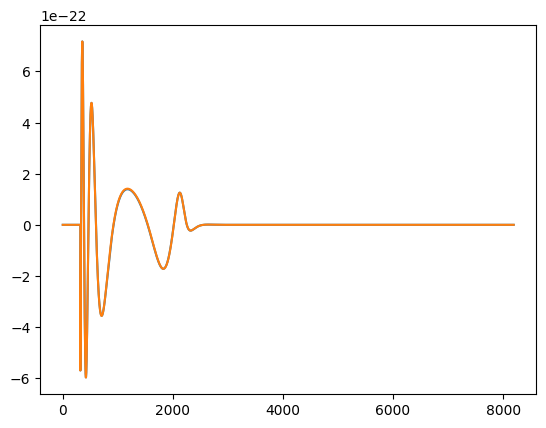

In [ ]:
pp.plot(hp_gr)
pp.plot(hp_gr_my)

In [ ]:
from pycbc.waveform import utils as wfutils


# hp_gr_fd2td = wfutils.fd_to_td(hp_gr,1/4096.,left_window=(19.5,20), left_beta=8)
hp_gr_fd2td = hp_gr.to_timeseries(delta_t=1/4096/2)

hp_gr_my_fd2td = hp_gr_my.to_timeseries(delta_t=1/4096/2)

pp.figure(figsize=(15,5))
# pp.plot(hp_gr_my.to_timeseries(delta_t=1/4096).data)
# pp.plot(hp_gr.to_timeseries(delta_t=1/4096).data)
pp.plot(hp_gr_fd2td.sample_times, hp_gr_fd2td)
pp.plot(hp_gr_my_fd2td.sample_times+0.0001, hp_gr_my_fd2td)
# pp.xlim(-0.5, 0.1)
# pp.xlim(-16,-15.8)


ValueError: The value of delta_t (0.0001220703125) would be undersampled. Maximum delta_t is 3.0517578125e-05.

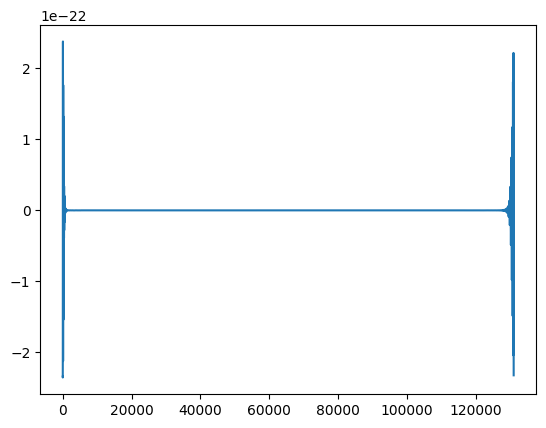

In [ ]:
pp.plot(hp_gr_fd2td - hp_gr_my_fd2td)

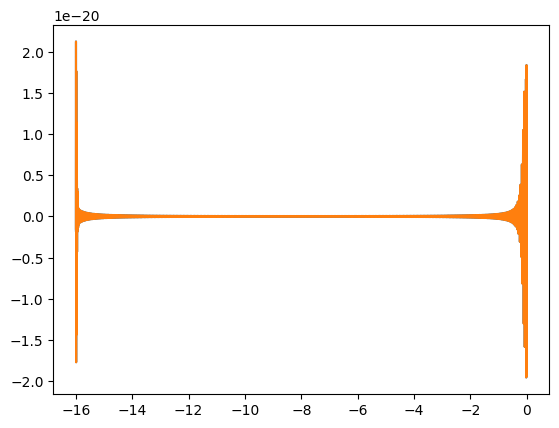

In [ ]:
pp.plot(hp_gr.to_timeseries(delta_t=1/4096).sample_times, hp_gr.to_timeseries(delta_t=1/4096))
pp.plot(hp_gr_my.to_timeseries(delta_t=1/4096).sample_times, hp_gr_my.to_timeseries(delta_t=1/4096))

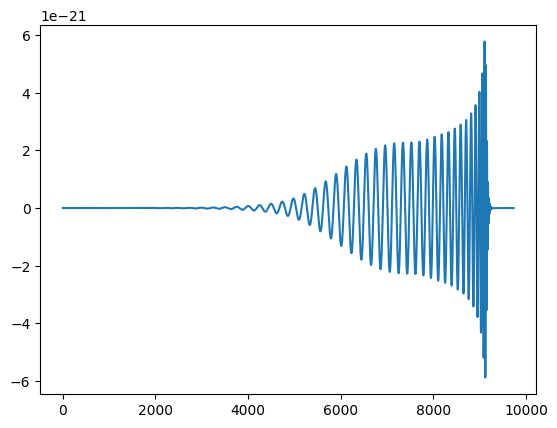

In [ ]:
# pp.plot(hp_gr_fd2td)
pp.plot(hp_gr_td)